In [1]:
library(repr) ; options(repr.plot.width=6, repr.plot.height= 6) # Change plot sizes (in cm)

# Biological Computing in R

```{admonition} Learning goals
**By the end of this chapter you should be able to:**
- Turn a simple biological question into an algorithm and check the result against an expected answer
- Write and run a self-contained R script from the root of a project
- Create, inspect and subset vectors, matrices, data frames and lists
- Use vectorized operations to calculate with several values at once
- Import a table, inspect its types and missing values, check simple assumptions and write a result
- Write functions that take arguments and return useful values
- Choose appropriately between vectorization, conditionals and loops
- Diagnose common errors and add explicit checks for important assumptions
- Install packages in a user library and load the packages a script needs
- Make and save a clear base-R figure
- Organize code, data and results so that an analysis can be rerun in a fresh R session
```

```{admonition} Prerequisites
:class: tip
The following experience is helpful but not essential:
- basic command-line and file-management skills from [UNIX and Linux](unix.ipynb); and
- organizing scripts, data and results in a project directory.

No prior R, Python or statistics knowledge is assumed. Variables, functions, loops and the statistical context needed for the examples are introduced where they are used. You will need a working R installation for the exercises; setup and editor options are covered in [Getting started with R](#getting-started-with-r).

Use your existing bootcamp project, or choose a learning project if you are studying R independently. See [Organising your learning project](../part-computing.md#organising-your-learning-project) and the R setup example under [Your analysis workflow](#your-analysis-workflow). You do not need a separate R coursework directory, or prior Python or Git study, to begin.
```

```{admonition} How the two R chapters fit together
:class: note
This chapter is about learning to express and check a computation in R. Near the end, you will bring these skills together using a small table of biological observations. [Data management and visualization in R](data-r.ipynb) carries on from there, asking what each row means, how a missing value differs from an observed zero, when to reshape a table, and how to make a figure that says what you intend. If you are taking both chapters in the same week, think of them as two parts of the same journey (to NiRvana!).
```

## Introduction

R is a free, open-source language and environment for statistical computing and graphics. It is particularly well suited to working with tabular data, fitting statistical models and producing reproducible visualizations.

R forms one part of the multilingual computing toolkit (recall [Why *Multilingual*?](../intro.md#why-multilingual)). The [Unix](unix.ipynb) and [Shell scripting](shell-scripting.ipynb) chapters provide tools for managing files and coordinating programs; [Python](python.ipynb) provides a general-purpose language for scientific programs and simulations; and R provides concise tools for data analysis, statistics and visualization. Code written in any of these languages can be tracked with [Git](git.ipynb) and incorporated into reports written in [LaTeX](latex.ipynb).

This is where we learn the R needed for the rest of MQB. If you have already worked with another programming language, you will recognize ideas such as variables, functions, conditionals and loops, although R expresses some of them differently. In the next R chapter, you will use these skills to decide how biological data should be organized, checked and plotted.

### From an algorithm to R

The [Shell scripting chapter](shell-scripting.ipynb#from-a-task-to-an-algorithm) introduced an **algorithm** as a precise sequence of steps for solving a problem (and more specifically, that can be encoded in way that a computer can execute it). 

The same algorithm can be implemented in different languages.

Consider the plant heights 8, 12, 10 and 15 cm. We want to count how many exceed 10 cm. The expected answer is **2**. In R, the complete calculation can be written as:

```r
heights <- c(8, 12, 10, 15)
sum(heights > 10)
```

The comparison `heights > 10` checks every value and produces a logical vector. `sum()` then counts the `TRUE` values. This is an example of **vectorization**, an important feature of R that we will develop throughout the chapter.

The biological question, decision rule and expected result are independent of the language. 

*What changes is how the algorithm is expressed (the language and its syntax).* The [Python chapter](python.ipynb#from-a-task-to-an-algorithm) uses the same example to make this explicit.

### Why R?

R is widely used in biological research because it combines:

* data structures designed for scientific and tabular data;
* extensive statistical and modelling capabilities;
* high-quality graphics, including the `ggplot2` ecosystem;
* vectorized operations for concise data processing;
* a large collection of community-developed packages; and
* scripts that preserve a reproducible record of an analysis.

Because an R analysis is represented as code, it can be checked, revised and rerun when data or assumptions change. The same script can also form one component of a larger workflow coordinated by the shell or Python. 

R and its packages are available for all common operating systems through the [Comprehensive R Archive Network (CRAN)](https://cran.r-project.org).

### R in a multilingual workflow

| Task | Typical tool |
| :--- | :--- |
| Manage files and coordinate commands | [Shell](shell-scripting.ipynb) |
| Write general scientific programs and simulations | [Python](python.ipynb) |
| Analyse data, fit statistical models and create figures | R |
| Record and share changes | [Git](git.ipynb) |
| Produce a scientific report | [LaTeX](latex.ipynb) |

These are typical strengths rather than rigid boundaries. For example, both R and Python can analyse data, create figures and call other programs. The aim is to choose tools that make each part of an analysis clear, testable and reproducible. Here we learn enough plotting to inspect and check a result; the [Data management and visualization in R](data-r.ipynb) chapter develops data wrangling and the grammar of graphics in depth.

## Getting started with R

First confirm that R is installed by running `R --version` and `Rscript --version` in a terminal. If either command is unavailable, follow [R Installation and User Libraries](../appendices/r-setup.md).

You can work in the R console or use an integrated development environment (IDE). This book supports both Visual Studio Code and RStudio; neither is required to understand the language. See [To IDE or not to IDE](../intro.md#to-ide-or-not-to-ide) for the general role of an IDE, [R Installation and User Libraries](../appendices/r-setup.md) for the runtime, and [Using R in VS Code](../appendices/vscode.md#using-r-in-vs-code) for the VS Code setup.

To start the command-line interface, type `R` in a terminal. You should see a prompt similar to the example below:

---

:::{figure-md} r-Linux-console

```{image} ./graphics/R_Linux.png
:alt: R console on Linux or macOS
:width: 500px
```

**The R console on Linux or macOS.**

:::

---


## R basics

Let's start with some R basics. Enter commands interactively at the R prompt (`>`); the up and down arrow keys move through your command history.

### Useful R commands

|Command| What it does|
|:-|:-|
| `ls()`| list the objects in the workspace |
| `rm('a', 'b')`| remove variable(s) `a` and `b`|
| `rm(list = ls())`| remove all objects from the workspace |
| `getwd()`| get current working directory |
| `setwd('Path')`| set the working directory to `Path` for the current session |
| `q()`| quit R |
| `?command`| show the documentation for `command` |
| `??keyword`| search installed help pages for `keyword` |

For reproducible scripts, start R in the project root and use [relative paths](../appendices/terms.md#paths-and-the-current-directory), such as `data/trees.csv`. Avoid putting a path that only exists on your computer in `setwd()`. See [Building your coursework directory structure](unix.ipynb#building-your-coursework-directory-structure).

### Baby steps

As in other programming languages, variables let you name values in an R session's workspace. Creating an object uses some of the computer's memory; for now, the important point is that the name lets you retrieve and work with that value.

&#9733; Now, let's try assigning a few variables in R and doing things to them:

In [2]:
a <- 4  # store 4 as variable a

In [3]:
a # display it

[1] 4

In [4]:
a * a # product

[1] 16

Store a variable:

In [5]:
a_squared <- a * a 

```{note}
R commonly uses the `<-` [assignment operator](https://stat.ethz.ch/r-manual/r-devel/library/base/html/assignOps.html). The `=` symbol can also assign values in some contexts and is used to match named function arguments; this chapter uses `<-` for assignment so that the two roles remain visually distinct.
```

In [6]:
sqrt(a_squared) # square root

[1] 4

Build a vector with `c` (stands for "`c`oncatenate"): 

In [7]:
v <- c(0, 1, 2, 3, 4)

In [8]:
v # Display the vector-valued variable you created

[1] 0 1 2 3 4

Note that any text after a `#` is ignored by R, as in many other languages — handy for commenting. 

*In general, please comment your code and scripts, for *everybody's* sake. You will be amazed by how difficult it is to read and understand what a certain R script does (or any other script, for that matter) without judicious comments &mdash; even scripts you yourself wrote not so long ago!

```{tip}

 **The Concatenate function:** `c()`(concatenate) is one of the most commonly used R functions because it is the default method for combining multiple arguments into a vector. To learn more about it, type `?c` at the R prompt and hit enter. 
```

In [9]:
is.vector(v) # check if v's a vector

[1] TRUE

In [10]:
mean(v) # mean

[1] 2

Thus, a *vector* is like a single column or row in a *spreadsheet* (just like it is in [Python](python.ipynb)). Multiple vectors can be combined to make a matrix (the full spreadsheet).  

This is one of many ways R stores and processes data. More on R data types and objects below.  

A single value (any kind) is a vector object of length 1 by default. That's why in the R console you see `[1]` before any single-value output (e.g., type `8`, and you will see `[1] 8`).

Some examples of operations on vectors: 

In [11]:
var(v) # variance

[1] 2.5

In [12]:
median(v) # median

[1] 2

In [13]:
sum(v) # sum all elements

[1] 10

In [14]:
prod(v + 1) # multiply

[1] 120

In [15]:
length(v) # how many elements in the vector

[1] 5

### Variable names and Tabbing

In R, you can name variables in the following way to keep track of related variables:

In [16]:
wing.width.cm <- 1.2 #Using dot notation

In [17]:
wing.length.cm <- c(4.7, 5.2, 4.8)

This can be handy; type:

```r
wing.
```

And then hit the `tab`key to reveal all variables in that  category. This is nice &mdash; variable names should be as obvious as possible. However, they should not be over-long either! Good style and readability is more important than just convenient variable names. 

In fact, R allows dots to be used in variable names of all objects (not just objects that are variables). For example, functions names can have dots in them as well, as you will see below with the `is.*` family (e.g., `is.infinite()`, `is.nan()`, etc.). 


```{tip}
Following a consistent style for different elements of your R code (syntax, conditionals, functions, etc) is important. The tidyverse [style guide](https://style.tidyverse.org/index.html)  is recommended. You should keep going back to different sections of the style guide as you learn new topics. Here, for starters, have a look at [naming conventions](https://style.tidyverse.org/syntax.html).  
```

### Operators
The usual operators are available in R:

|Operator||
|:-|:-|
| `+`| Addition |
| `-`| Subtraction|
| `*`| Multiplication|
| `/`| Division|
| `^`| Power|
| `%%`| Modulo|
| `%/%`| Integer division|
| `==`| Equals|
| `!=`| Differs|
| `>`| Greater|
| `>=`| Greater OR Equal|
| `&`| Logical AND|
| `\|` |  Logical OR|
| `!`| Logical NOT|

### When things go wrong

Here are some common syntax errors that you might run into in R, especially when you are just beginning to learn this language: 


* Missing a closing bracket leads to continuation line, which looks something like this, with a `+` at the end:

```r
x <- (1 + (2 * 3)
+ 
```

Hit `Ctrl-C` (UNIX terminal or base R command line) or ESC (in RStudio) or keep typing!

* Too many parentheses; for example, `2 + (2*3))`

* Wrong or mismatched brackets (see next subsection)

* Mixing double and single quotes will also give you an error


When things are taking too long and the R console seems frozen, try `Ctrl + C` (UNIX terminal or base R command line) or ESC (in RStudio) to force an exit from whatever is going on.

### Types of parentheses

R has specific uses for different types of Parentheses type that you need to get used to:

| Parentheses type| What it does|
|:-|:-|
|`f(3,4)`| call the function (or command) f, with the arguments 3 & 4. |
|`a + (b*c)`| to enforce order over which statements or calculations are executed. Here `(b*c)`is executed before adding to `a`. Here is an alternative order: `(a + b)*c`|
|`{expr1; expr2;...exprn}` | group a set of expressions or commands into one compound expression. Value returned is value of last expression; used in building function, loops, and conditionals (more on these soon!).|
|`x[4]`| get the 4th element of the vector `x`.|
| `li[[3]]`| get the 3rd element of some list `li`, and return it.(compare with `li[3]`, which returns a list with just the 3rd element inside). More on lists in next section.

In [18]:
li = list(c(1,2,3))

In [19]:
class(li)

[1] "list"

## Variable types

There are different kinds of data variable types in R, but you will basically need to know four for most of your work: integer, float (or "numeric", including real numbers), string (or "character", e.g., 
text), and Boolean ("logical"; `True`or `FALSE`).  

Try this:

In [20]:
v <- TRUE

In [21]:
v

[1] TRUE

In [22]:
class(v)

[1] "logical"

The `class()` function tells you what type of variable any object in the workspace is.

In [23]:
v <- 3.2
class(v)

[1] "numeric"

In [24]:
v <- 2L
class(v)

[1] "integer"

In [25]:
v <- "A string"
class(v)

[1] "character"

In [26]:
b <- NA
class(b)

[1] "logical"

Also, the `is.*` family of functions allow you to check if a variable is a specific in R: 

In [27]:
is.na(b)

[1] TRUE

In [28]:
b <- 0/0
b

[1] NaN

In [29]:
is.nan(b)

[1] TRUE

In [30]:
b <- 5/0
b

[1] Inf

In [31]:
is.nan(b)

[1] FALSE

```{tip}
Beware of the difference between `NA` (`N`ot` A`vailable) and `NaN` (`N`ot` a N`umber). R will use `NA`to represent/identify missing values in data or outputs, while `NaN`represent nonsense values (e.g., 0/0) that cannot be represented as a number or some other data type. 

See what R has to say about this: try `?is.nan`, `?is.na`, `?NA`, `?NaN`in the R commandline (one at a time!).

There are also `Inf` (Infinity, e.g., 1/0), and `NULL` (variable not set) value types. Look these up as well using `?`.
```

In [32]:
is.infinite(b)

[1] TRUE

In [33]:
is.finite(b)

[1] FALSE

In [34]:
is.finite(0/0)

[1] FALSE

### Type Conversions and Special Values

The `as.*` commands all convert a variable from one type to another. Try out the following examples:

In [35]:
as.integer(3.1)

[1] 3

In [36]:
as.numeric(4)

[1] 4

In [37]:
as.roman(155)

[1] CLV

In [38]:
as.character(155)  # same as converting to string

[1] "155"

In [39]:
as.logical(5)

[1] TRUE

*What just happened?!* R maps all values other than `0` to logical `TRUE`, and `0` to `FALSE`. This can be useful, for example, when you want to convert data to presence or absence.

In [40]:
as.logical(0)

[1] FALSE

Also, *keep an eye out for [E notation](https://en.wikipedia.org/wiki/Scientific_notation) in outputs of R functions for statistical analyses, and learn to interpret numbers formatted this way.* R uses E notation in outputs of statistical tests to display  very large or small numbers. If you are not used to different  representations of long numbers, the E notation might be  confusing. 

Try this:

In [41]:
1E4

[1] 10000

In [42]:
1e4

[1] 10000

In [43]:
5e-2

[1] 0.05

In [44]:
1E4^2

[1] 1e+08

In [45]:
1 / 3 / 1e8

[1] 3.333333e-09

```{tip}
**Boolean values in R:** Write `TRUE` and `FALSE` in full. R also recognizes `T` and `F`, but these are ordinary variable names and can be reassigned. The full forms are safer and easier to read. For example:

```r
a <- TRUE
```

Type `a` in the R console to see the value stored in it.
```

## R Data Structures

R comes with different built-in structures (objects) for data storage and manipulation. Mastering these, and knowing which one to use when will help you write better, more efficient programs and also handle diverse datasets (numbers, counts, names, dates, etc):

| | |
|:-  |:- | 
|*Vector*: |An ordered collection of any of the R data types (see above). All the elements of a vector must be of the sane data type. Vectors are one-dimensional -- *like a single cell, column or row in a spreadsheet*.|
|*Matrix*: | A 2 dimensional vector (has both rows and columns). Like vectors, can only store data of one type in any one instance of this data structure.|
|*Array*: | for storing data in more than two dimensions (e.g., a stack of 2-D matrices). Like vectors, can only store data of one type in any one instance of this data structure|
|*List*: | One-dimensional like vectors but can contain mixed data types|
|*Dataframe*: | Most versatile, can contain mixed data, and also column and row names|


```{note}
**Data "structures" vs. "objects" in R**: You will often see the terms "object" and "data structure" in this and other chapters. A data structure is a way of organising data, such as a vector or data frame. In R, values, functions and fitted models can all be objects. Each kind of object has its own rules for the operations that R can perform on it. 
```

### Vectors
The Vector, which you have already seen above in the R warmup, is a fundamental data structure in R. Scalars (single data values) are treated as vector of length 1. 

*Basically, a vector is like a single cell, column or row in a spreadsheet, but with the constraint that all elements have tio be the same data type.*

&#9733; Now get back into R (if you somehow quit R using `q()` or something else), and try this:

In [46]:
a <- 5
is.vector(a)

[1] TRUE

In [47]:
v1 <- c(0.02, 0.5, 1)
v2 <- c("a", "bc", "def", "ghij")
v3 <- c(TRUE, TRUE, FALSE)

In [48]:
v1;v2;v3

[1] 0.02 0.50 1.00

[1] "a"    "bc"   "def"  "ghij"

[1]  TRUE  TRUE FALSE

R vectors can only store data of a single type (e.g., all numeric or all character). If you try to combine different types, R will homogenize everything to the same data type. To see this, try the following:

In [49]:
v1 <- c(0.02, TRUE, 1)
v1

[1] 0.02 1.00 1.00

When R combines `TRUE` with numbers in one vector, it converts `TRUE` to 1 so that every element has the same data type.

In [50]:
v1 <- c(0.02, "Mary", 1)
v1

[1] "0.02" "Mary" "1"

Everything gets converted to text!

Basically, the function `c` "coerces" arguments that are of mixed types (strings/text, real numbers, logical arguments, etc) to a common type.

You create empty vectors like this instead of using `c()`:

In [51]:
v2 <- character(3) # an empty vector 'character' with 3 elements
v2

[1] "" "" ""

In [52]:
v3 <- numeric(3) # an empty numeric 'character' with 3 elements
v3

[1] 0 0 0

#### From an algorithm to R

Return to the introduction's question: how many of the heights 8, 12, 10 and 15 cm exceed 10 cm? We predicted **2** before writing code. Now store the heights in a vector and compare every element with the threshold:

```r
heights_cm <- c(8, 12, 10, 15)
above_threshold <- heights_cm > 10
above_threshold
sum(above_threshold)
```

`heights_cm > 10` applies the same comparison to each height and produces `FALSE TRUE FALSE TRUE`. When `sum` adds logical values, `TRUE` contributes 1 and `FALSE` contributes 0, so the result is **2**, matching our prediction. The height of exactly 10 cm is not counted. What would change if the question asked for heights of at least 10 cm?

This is a **vectorized implementation**: R applies the comparison across the vector without an explicit loop in our code. The introduction's counter procedure and this compare-and-sum procedure solve the same problem using different steps. The decision rule and expected result are unchanged; a loop is not the only way to implement the task.

All measurements here are present and in centimetres. If a measurement is missing (`NA`), the comparison and sum can also be `NA`. Deciding whether to exclude missing measurements is a scientific choice, not merely a way to obtain a number.


(r-matrices)=
### Matrices and Arrays

An R "matrix" is a 2 dimensional vector (has both rows and columns) and a "array" can store data in more than two dimensions (e.g., a stack of 2-D matrices). 

R has many functions to build and manipulate matrices and arrays. 

Try this:

In [53]:
mat1 <- matrix(1:25, 5, 5)
mat1

1,6,11,16,21
2,7,12,17,22
3,8,13,18,23
4,9,14,19,24
5,10,15,20,25


Note that the output in your terminal or console will be more like:

In [54]:
print(mat1)

     [,1] [,2] [,3] [,4] [,5]
[1,]    1    6   11   16   21
[2,]    2    7   12   17   22
[3,]    3    8   13   18   23
[4,]    4    9   14   19   24
[5,]    5   10   15   20   25


(even if you don't use the `print()` command)

The output looks different above because the R code is running in a jupyter notebook. 

Now try this:

In [55]:
mat1 <- matrix(1:25, 5, 5, byrow=TRUE)
mat1

1,2,3,4,5
6,7,8,9,10
11,12,13,14,15
16,17,18,19,20
21,22,23,24,25


That is, you can order the elements of a matrix by row instead of column (default).

In [56]:
dim(mat1) #get the size of the matrix

[1] 5 5

To make an array consisting of two 5$\times$5 matrices containing the integers 1-50:

In [57]:
arr1 <- array(1:50, c(5, 5, 2))
arr1[,,1]

1,6,11,16,21
2,7,12,17,22
3,8,13,18,23
4,9,14,19,24
5,10,15,20,25


In [58]:
print(arr1)

, , 1

     [,1] [,2] [,3] [,4] [,5]
[1,]    1    6   11   16   21
[2,]    2    7   12   17   22
[3,]    3    8   13   18   23
[4,]    4    9   14   19   24
[5,]    5   10   15   20   25

, , 2

     [,1] [,2] [,3] [,4] [,5]
[1,]   26   31   36   41   46
[2,]   27   32   37   42   47
[3,]   28   33   38   43   48
[4,]   29   34   39   44   49
[5,]   30   35   40   45   50



In [59]:
arr1[,,2]

26,31,36,41,46
27,32,37,42,47
28,33,38,43,48
29,34,39,44,49
30,35,40,45,50


Just like R vectors, R matrices and arrays have to be of a homogeneous type, and R will do the same sort of type homogenization you saw for R vectors above. 

Try inserting a text value in `mat1`and see what happens: 

In [60]:
mat1[1,1] <- "one"
mat1

one,2,3,4,5
6,7,8,9,10
11,12,13,14,15
16,17,18,19,20
21,22,23,24,25


`mat1` went from being `A matrix: 5 × 5 of type int` to `A matrix: 5 × 5 of type chr`. That is, inserting a string in one location converted all the elements of the matrix to the `chr` (string) data type.

Thus R's matrix and array are similar to Python's `numpy` array and matrix data structures.

### Lists

A list is one-dimensional data structure that can be used to store a group of data objects of different sizes and types (e.g., one whole data frame and one vector can both be in a single list). It is simply an ordered collection of objects (that can be variables). 

```{note}
The outputs of many statistical functions in R are lists (e.g. linear model fitting using `lm()`), to return all relevant information in one output object. So you need to know how to unpack and manipulate lists. 
```

As a budding multilingual quantitative biologist, you should not be perturbed by the fact that a `list` is a very different data structure in Python vs R. It will take some practice &mdash; the good thing is that this sort of inconsistency is less common than in human languages where the same word far too often means different things in different  languages!

Try this:

In [61]:
MyList <- list(1L, "p", FALSE, .001) # an integer, a character, a boolean, and a numeric walk into a bar...
MyList

[[1]]
[1] 1

[[2]]
[1] "p"

[[3]]
[1] FALSE

[[4]]
[1] 0.001

A more complex (and meaningful) list:

In [62]:
MyList <- list(species=c("Quercus robur","Fraxinus excelsior"), age=c(123, 84))
MyList

$species
[1] "Quercus robur"      "Fraxinus excelsior"

$age
[1] 123  84

You can access contents of a list item using number of the item instead of name using nested square brackets:

In [63]:
MyList[[1]]

[1] "Quercus robur"      "Fraxinus excelsior"

In [64]:
MyList[[1]][1]

[1] "Quercus robur"

or using the name in either this way:

In [65]:
MyList$species

[1] "Quercus robur"      "Fraxinus excelsior"

or this way:  

In [66]:
MyList[["species"]]

[1] "Quercus robur"      "Fraxinus excelsior"

And to access a specific element inside a list's item 

In [67]:
MyList$species[1]

[1] "Quercus robur"

A more complex list:

In [68]:
pop1<-list(species='Cancer magister',
           latitude=48.3,longitude=-123.1,
           startyr=1980,endyr=1985,
           pop=c(303,402,101,607,802,35))
pop1

$species
[1] "Cancer magister"

$latitude
[1] 48.3

$longitude
[1] -123.1

$startyr
[1] 1980

$endyr
[1] 1985

$pop
[1] 303 402 101 607 802  35

You can build lists of lists too:

In [69]:
pop1<-list(lat=19,long=57,
           pop=c(100,101,99))
pop2<-list(lat=56,long=-120,
           pop=c(1,4,7,7,2,1,2))
pop3<-list(lat=32,long=-10,
           pop=c(12,11,2,1,14))
pops<-list(sp1=pop1,sp2=pop2,sp3=pop3)
pops

$sp1
$sp1$lat
[1] 19

$sp1$long
[1] 57

$sp1$pop
[1] 100 101  99


$sp2
$sp2$lat
[1] 56

$sp2$long
[1] -120

$sp2$pop
[1] 1 4 7 7 2 1 2


$sp3
$sp3$lat
[1] 32

$sp3$long
[1] -10

$sp3$pop
[1] 12 11  2  1 14

In [70]:
pops$sp1 # check out species 1

$lat
[1] 19

$long
[1] 57

$pop
[1] 100 101  99

In [71]:
pops$sp1["pop"] # sp1's population sizes

$pop
[1] 100 101  99

In [72]:
pops[[2]]$lat #latitude of second species

[1] 56

In [73]:
pops[[3]]$pop[3]<-102 #change population of third species at third time step
pops

$sp1
$sp1$lat
[1] 19

$sp1$long
[1] 57

$sp1$pop
[1] 100 101  99


$sp2
$sp2$lat
[1] 56

$sp2$long
[1] -120

$sp2$pop
[1] 1 4 7 7 2 1 2


$sp3
$sp3$lat
[1] 32

$sp3$long
[1] -10

$sp3$pop
[1]  12  11 102   1  14

### Data frames

This is a very important data structure in R. Unlike matrices and vectors, R data frames can store data in which each column contains a different data type (e.g., numbers, strings, boolean) or even a combination of data types, just like a standard spreadsheet. Indeed, dataframes were built to emulate some of the convenient properties of spreadsheets. Many statistical and plotting functions and packages in R naturally use data frames. 

Let's build and manipulate a dataframe. First create three vectors:

In [74]:
Col1 <- 1:10
Col1

[1]  1  2  3  4  5  6  7  8  9 10

In [75]:
Col2 <- LETTERS[1:10]
Col2

[1] "A" "B" "C" "D" "E" "F" "G" "H" "I" "J"

In [76]:
Col3 <- runif(10) # 10 random numbers from a uniform distribution
Col3

[1] 0.52450244 0.06864634 0.10853537 0.02253084 0.77763883 0.70535061
 [7] 0.15959064 0.35984396 0.21005358 0.61282043

Now combine them into a dataframe:

In [77]:
MyDF <- data.frame(Col1, Col2, Col3)
MyDF

Col1,Col2,Col3
<int>,<chr>,<dbl>
1,A,0.52450244
2,B,0.06864634
3,C,0.10853537
4,D,0.02253084
5,E,0.77763883
6,F,0.70535061
7,G,0.15959064
8,H,0.35984396
9,I,0.21005358


Again, this output looks different from your terminal/console output because these commands are running in a Jupyter notebook.

Your output will look like this:

In [78]:
print(MyDF)

   Col1 Col2       Col3
1     1    A 0.52450244
2     2    B 0.06864634
3     3    C 0.10853537
4     4    D 0.02253084
5     5    E 0.77763883
6     6    F 0.70535061
7     7    G 0.15959064
8     8    H 0.35984396
9     9    I 0.21005358
10   10    J 0.61282043


```{note}
Maybe you have guessed by now that R data frames are actually a kind of list. That is, a R data frame is in fact a `list` of equal-length `vector`s (a “rectangular” list).
```

You can easily assign names to the columns of dataframes:

In [79]:
names(MyDF) <- c("MyFirstColumn", "My Second Column", "My.Third.Column")
MyDF

MyFirstColumn,My Second Column,My.Third.Column
<int>,<chr>,<dbl>
1,A,0.52450244
2,B,0.06864634
3,C,0.10853537
4,D,0.02253084
5,E,0.77763883
6,F,0.70535061
7,G,0.15959064
8,H,0.35984396
9,I,0.21005358


And unlike matrices, you can access the contents of data frames by naming the columns directly using a $ sign:

In [80]:
MyDF$MyFirstColumn

[1]  1  2  3  4  5  6  7  8  9 10

But don't use spaces in column names! Try this: 

In [81]:
MyDF$My Second Column

ERROR: Error in parse(text = input): <text>:1:9: unexpected symbol
1: MyDF$My Second
            ^


That gives an error, because R cannot handle spaces in column names easily. 

So replace that column name using the `colnames` function:

In [82]:
colnames(MyDF)

[1] "MyFirstColumn"    "My Second Column" "My.Third.Column"

In [83]:
colnames(MyDF)[2] <- "MySecondColumn"
MyDF

MyFirstColumn,MySecondColumn,My.Third.Column
<int>,<chr>,<dbl>
1,A,0.52450244
2,B,0.06864634
3,C,0.10853537
4,D,0.02253084
5,E,0.77763883
6,F,0.70535061
7,G,0.15959064
8,H,0.35984396
9,I,0.21005358


But using dots in column names is OK (just as it is for variable names): 

In [84]:
MyDF$My.Third.Column

[1] 0.52450244 0.06864634 0.10853537 0.02253084 0.77763883 0.70535061
 [7] 0.15959064 0.35984396 0.21005358 0.61282043

You can also access elements by using numerical indexing:   

In [85]:
MyDF[,1]

[1]  1  2  3  4  5  6  7  8  9 10

That is, you asked R to return values of `MyDF` in all rows (therefore, nothing before the comma), and the first column (`1` after the comma).

In [86]:
MyDF[1,1]

[1] 1

In [87]:
MyDF[c("MyFirstColumn","My.Third.Column")] # show two specific columns only

MyFirstColumn,My.Third.Column
<int>,<dbl>
1,0.52450244
2,0.06864634
3,0.10853537
4,0.02253084
5,0.77763883
6,0.70535061
7,0.15959064
8,0.35984396
9,0.21005358


You can check whether a particular object is a dataframe data structure with:

In [88]:
class(MyDF)

[1] "data.frame"

You can check the structure of a dataframe with `str()`:

In [89]:
str(MyDF)

'data.frame':	10 obs. of  3 variables:
 $ MyFirstColumn  : int  1 2 3 4 5 6 7 8 9 10
 $ MySecondColumn : chr  "A" "B" "C" "D" ...
 $ My.Third.Column: num  0.5245 0.0686 0.1085 0.0225 0.7776 ...


You can print the column names and top few rows with `head()`:

In [90]:
head(MyDF)

,MyFirstColumn,MySecondColumn,My.Third.Column
,<int>,<chr>,<dbl>
1,1,A,0.52450244
2,2,B,0.06864634
3,3,C,0.10853537
4,4,D,0.02253084
5,5,E,0.77763883
6,6,F,0.70535061


And the bottom few rows with `tail()`:

In [91]:
tail(MyDF)

,MyFirstColumn,MySecondColumn,My.Third.Column
,<int>,<chr>,<dbl>
5,5,E,0.7776388
6,6,F,0.7053506
7,7,G,0.1595906
8,8,H,0.3598440
9,9,I,0.2100536
10,10,J,0.6128204


```{note}
**The Factor data type**: R has a special data type called "factor". Different values in this data type are called "levels". This data type is used to identify "grouping variables" such as columns in a dataframe that contain  experimental treatments. This is convenient for statistical analyses using one of the many plotting and statistical commands or routines available in R, which have been written to interpret the `factor` data type as such and use it to automatically compare subgroups in the data. More on this later, when we delve into analyses (including visualization) in R. 
```


### Matrix vs Dataframe

If dataframes are so nice, why use R matrices at all? The problem is that dataframes can be too slow when large numbers of mathematical calculations or operations (e.g., matrix - vector multiplications or other linear algebra operations) need to be performed. In such cases, you will need to convert a dataframe to a matrix. But for statistical analyses, plotting, and writing output of standard R analyses to a file, data frames are more convenient. Dataframes also allow you to refer to columns by name (using `$`), which is often convenient.

To see the difference in memory usage of matrices vs dataframes, try this:

In [92]:
MyMat = matrix(1:8, 4, 4)
MyMat

1,5,1,5
2,6,2,6
3,7,3,7
4,8,4,8


In [93]:
MyDF = as.data.frame(MyMat)
MyDF

V1,V2,V3,V4
<int>,<int>,<int>,<int>
1,5,1,5
2,6,2,6
3,7,3,7
4,8,4,8


In [94]:
object.size(MyMat) # returns size of an R object (variable) in bytes

280 bytes

In [95]:
object.size(MyDF)

1152 bytes

Quite a big difference!

## Creating and manipulating data

(r-creating-sequences)=
### Creating sequences

The `:` operator creates vectors of sequential integers:

In [96]:
years <- 1990:2009
years

[1] 1990 1991 1992 1993 1994 1995 1996 1997 1998 1999 2000 2001 2002 2003 2004
[16] 2005 2006 2007 2008 2009

In [97]:
years <- 2009:1990 # or in reverse order 
years

[1] 2009 2008 2007 2006 2005 2004 2003 2002 2001 2000 1999 1998 1997 1996 1995
[16] 1994 1993 1992 1991 1990

For sequences of float numbers, you have to use `seq()`:

In [98]:
seq(1, 10, 0.5)

[1]  1.0  1.5  2.0  2.5  3.0  3.5  4.0  4.5  5.0  5.5  6.0  6.5  7.0  7.5  8.0
[16]  8.5  9.0  9.5 10.0

```{tip}
Don't forget, you can get help on a particular R command by prefixing it with `?`. For example, try:

`?seq`
```

You can also use `seq(from = 1, to = 10, by = 0.5)` or `seq(from = 1, by = 0.5, to = 10)` with the same effect (try it). This explicit, "argument matching" approach is partly what makes R so popular and accessible to a wider range of users.

(r-indices)=

### Accessing parts of data stuctures: Indices and Indexing

Every element (entry) of a vector in R has an order (an "index" value): the first value, second, third, etc. To illustrate this, let's create a simple vector:

In [99]:
MyVar <- c( 'a' , 'b' , 'c' , 'd' , 'e' )

Then, square brackets extract values based on their numerical order in the vector:

In [100]:
MyVar[1] # Show element in first position 

[1] "a"

In [101]:
MyVar[4] # Show element in fourth position 

[1] "d"

The values in square brackets are called "indices" &mdash; they give the index (position) of the required value. We can also select sets of values in different orders, or repeat values:

In [102]:
MyVar[c(3,2,1)] # reverse order

[1] "c" "b" "a"

In [103]:
MyVar[c(1,1,5,5)] # repeat indices

[1] "a" "a" "e" "e"

You can also manipulate data structures/objects by indexing:

In [104]:
v <- c(0, 1, 2, 3, 4) # Create a vector named v

In [105]:
v[3] # access one element

[1] 2

In [106]:
v[1:3] # access sequential elements

[1] 0 1 2

In [107]:
v[-3] # remove elements

[1] 0 1 3 4

In [108]:
v[c(1, 4)] # access non-sequential indices

[1] 0 3

For matrices, you need to use both row and column indices:

In [109]:
mat1 <- matrix(1:25, 5, 5, byrow=TRUE) #create a matrix
mat1

1,2,3,4,5
6,7,8,9,10
11,12,13,14,15
16,17,18,19,20
21,22,23,24,25


In [110]:
mat1[1,2]

[1] 2

In [111]:
mat1[1,2:4]

[1] 2 3 4

In [112]:
mat1[1:2,2:4]

2,3,4
7,8,9


And to get all elements in a particular row or column, you need to leave the value blank:

In [113]:
mat1[1,] # First row, all columns

[1] 1 2 3 4 5

In [114]:
mat1[,1] # First column, all rows

[1]  1  6 11 16 21

(r-recycling)=
### Recycling

When vectors are of different lengths, R will recycle the shorter one to make a vector of the same length:

In [115]:
a <- c(1,5) + 2
a

[1] 3 7

In [116]:
x <- c(1,2); y <- c(5,3,9,2)
x;y

[1] 1 2

[1] 5 3 9 2

In [117]:
x + y

[1]  6  5 10  4

Strange! R just recycled `x` (repeated `1,2` twice) so that the two vectors could be summed! here's another example:

In [118]:
x + c(y,1)

Warning message in x + c(y, 1):
“longer object length is not a multiple of shorter object length”


[1]  6  5 10  4  2

*Think about what happened here*. R is clearly not comfortable doing this, so it warns you! recycling could be convenient at times, but is dangerous!

### Basic vector-matrix operations

You can perform the usual vector and matrix operations on R vectors.

In [119]:
v <- c(0, 1, 2, 3, 4)
v2 <- v*2 # multiply whole vector by 2
v2

[1] 0 2 4 6 8

In [120]:
v * v2 # element-wise product

[1]  0  2  8 18 32

In [121]:
t(v) # transpose the vector

0,1,2,3,4


In [122]:
v %*% t(v) # matrix/vector product

0,0,0,0,0
0,1,2,3,4
0,2,4,6,8
0,3,6,9,12
0,4,8,12,16


In [123]:
v3 <- 1:7 # assign using sequence
v3

[1] 1 2 3 4 5 6 7

In [124]:
v4 <- c(v2, v3) # concatenate vectors
v4

[1] 0 2 4 6 8 1 2 3 4 5 6 7

### Strings and Pasting

It is important to know how to handle strings in R for two main reasons:

* To deal with text data, such as names of experimental treatments 
* To generate appropriate text labels and titles for figures

Let's try creating and manipulating strings:

In [125]:
species.name <- "Quercus robur" #You can alo use single quotes
species.name

[1] "Quercus robur"

To combine to strings: 

In [126]:
paste("Quercus", "robur")

[1] "Quercus robur"

In [127]:
paste("Quercus", "robur",sep = "") #Get rid of space

[1] "Quercusrobur"

In [128]:
paste("Quercus", "robur",sep = ", ") #insert comma to separate

[1] "Quercus, robur"

As you can see above, both double and single quotes work, but using double quotes is better because it will allow you to define strings that contain a single quotes, which is often necessary.

And as is the case with so many R functions, pasting works on vectors:

In [129]:
paste('Year is:', 1990:2000)

[1] "Year is: 1990" "Year is: 1991" "Year is: 1992" "Year is: 1993"
 [5] "Year is: 1994" "Year is: 1995" "Year is: 1996" "Year is: 1997"
 [9] "Year is: 1998" "Year is: 1999" "Year is: 2000"

Note that this last example creates a vector of 11 strings as it is 1990:2000 *inclusive*. 

## Useful R functions

There are a number of very useful functions available by default (in the "base packages"). Some particularly useful ones are listed below.

### For manipulating strings

|Function||
|:-|:-|
|`strsplit(x,';')`| Split the string `x` at ';' |
|`nchar(x)`| Number of characters in string `x`|
|`toupper(x)`| Set string `x` to upper case|
|`tolower(x)`| Set string `x` to lower case|
|`paste(x1,x2,sep=';')`| Join the two strings using ';'|

### Mathematical

|Function||
|:-|:-|
|`log(x)`| Natural logarithm of the number (or every number in the vector or matrix) `x`|
|`log10(x)`| Logarithm in base 10 of the number (or every number in the vector or matrix) `x`|
|`exp(x)`| Exponential of the number (or every number in the vector or matrix) `x` ($e^x$)|
|`abs(x)`| Absolute value of the number (or every number in the vector or matrix) `x`|
|`floor(x)`| Largest integer smaller than the number (or every number in the vector or matrix) `x` (i.e, round *down* to the nearest integer)|
|`ceiling(x)`| Smallest integer greater than the number (or every number in the vector or matrix) `x` (i.e, round *up* to the nearest integer)|
|`sqrt(x)`| Square root of the number (or every number in the vector or matrix) `x` ($\sqrt{x}$)|
|`sin(x)`| Sine function of the number (or every number in a vector or matrix) `x`|
|`pi`| Value of the constant $\pi$|

### Statistical

|Function||
|:-|:-|
|`mean(x)`| Compute mean of (a vector or matrix) `x`| 
|`sd(x)`| Standard deviation of (a vector or matrix) `x`|
|`var(x)`| Variance of (a vector or matrix) `x`|
|`median(x)`| Median of (a vector or matrix) `x`|
|`quantile(x,0.05)`| Compute the 0.05 quantile of (a vector or matrix) `x`|
|`range(x)`| range of the data in (a vector or matrix) `x`|
|`min(x)`| Minimum of (a vector or matrix) `x`|
|`max(x)`| Maximum of (a vector or matrix) `x`|
|`sum(x)`| Sum all elements of (a vector or matrix) `x`|
|`summary(x)`| Summary statistics for (a vector or matrix) `x`|

### Sets

|Function||
|:-|:-|
|`union(x, y)` | Union of all elements of two vectors x & y|
|`intersect(x, y)`|Elements common to two vectors x & y|
|`setdiff(x, y)`|Elements unique to two vectors x & y|
|`setequal(x, y)`|Check if two vectors x & y are the same set (have same unique elements)|
|`is.element(x, y)`|Check if an element x is in vector y (same as `x %in% y`)|

&#9733; *Try out the above commands in your R console by generating the appropriate data*. For example, 

In [130]:
strsplit("String; to; Split",';')# Split the string at ';'

[[1]]
[1] "String" " to"    " Split"

(r-random-numbers)=
### Generating random Numbers

You will probably need to generate random numbers at some point as a quantitative biologist. 

R has many routines for generating random samples from various probability distributions. There are a number of random number distributions that you can sample or generate random numbers from: 

|Function||
|:-|:-|
|`rnorm(10, m=0, sd=1)`| Draw 10 normal random numbers with mean=0 and standard deviation = 1|
|`dnorm(x, m=0, sd=1)` | Density function|
|`qnorm(x, m=0, sd=1)` | Cumulative density function|
|`runif(20, min=0, max=2)` | Twenty random numbers from uniform `[0,2]`|
|` rpois(20, lambda=10)` | Twenty random numbers from Poisson (with mean $\lambda$)|

#### "Seeding" random number generators   

Computers *can't* generate *true* mathematically random numbers. This may seem surprising, but basically a computer cannot be programmed to do things purely by chance; it can only follow given instructions blindly and is therefore completely predictable. Instead, computers have algorithms called "pseudo-random number generators" that generate *practically random* sequences of numbers. These are typically based on a iterative formula that generates a sequence of random numbers, starting with a first number called the "**seed**". This sequence is completely "deterministic", that is, starting with a particular seed yields exactly the same sequence of pseudo-random numbers every time you re-run the generator. 

Try this:

In [131]:
set.seed(1234567)
rnorm(1)

[1] 0.1567038

Everybody in the class  will get the same answer! 

Now try and compare the results with your neighbor:

In [132]:
rnorm(10)

[1]  1.373811191  0.730670244 -1.350800927 -0.008514961  0.320981863
 [6] -1.778148409  0.909503835 -0.919404336 -0.157714831  1.101997389

And then the whole sequence of 11 numbers you generated:

In [133]:
set.seed(1234567)
rnorm(11)

[1]  0.156703769  1.373811191  0.730670244 -1.350800927 -0.008514961
 [6]  0.320981863 -1.778148409  0.909503835 -0.919404336 -0.157714831
[11]  1.101997389

Thus, setting the seed allows you to reliably generate the identical sequence of "random" numbers. These numbers are not truly random, but have the properties of random numbers. Note also that pseudo-random number generators are periodic, which means that the sequence will eventually repeat itself. However, this  period is so long that it can be ignored for most practical purposes. So effectively, `rnorm` has an enormous list that it cycles through. The random seed starts the process, i.e., indicates where in the list to start. This is usually taken from the clock when you start R.

But why bother with random number seeds? Setting a particular seed can be useful when debugging programs (coming up below). Bugs in code can be hard to find &mdash; harder still if you are generating random numbers, so repeat runs of your code may or may not all trigger the same behavior. You can set the seed once at the beginning of the code &mdash; ensuring repeatability, retaining (pseudo) randomness. Once  debugged, if you want, you can remove the set seed line.

## Your analysis workflow

An R analysis usually reads data, runs code and creates several results. Keep these files in a clear project structure, whether you use R alone or alongside Bash and Python. Store scripts in `code/`, source data in `data/` and generated output in `results/`. Start R at the project root so that all three directories have stable, predictable paths.

Thus, your typical R analysis workflow will be:

---

:::{figure-md} r-project-org

```{image} ./graphics/RWorkflow.png
:alt: R Project Organization
:width: 600px
```

**R within your project.** Scripts come from `code/`, inputs from `data/`, and outputs go to `results/`. The same layout works for an R-only analysis or a multilingual project.

:::

---

Some details on each kind of file:

* *R script files*: These are plain text files containing all the R code needed for an analysis. These should be created with a text editor, typically part of some smart code editor like VS Code or RStudio, and saved with the extension `.R`. You should *never* use Word to save or edit these files as R can only read code from plain text files.

* *Text data files*: These are files of data in plain text format containing one or more columns of data (numbers, strings, or both). Although there are several format options, we will typically be using `csv` files, where the data entries are separated by commas. These are easy to create and export from Excel (if that's what you use...).

* *Results output files*: These are plain text files containing your results, such as the summary of output of a regression or ANOVA analysis. Typically, you will output your results in a table format where the columns are separated by commas (CSV) or tabs (tab-delimited).

* *Graphics files*: R can export graphics in a wide range of formats. This can be done automatically from R code and we will look at this later, but you can also select a graphics window (e.g., in RStudio) and click `File` $\triangleright$ `Save as...`.

* *RData files*: You can save any data loaded or created in R, including outputs of statistical analyses and other things, into a single `RData` file. These are not plain text and can only be read by R, but can hold all the data from an analysis in a single handy location. We will not use these much in this course.

Do you already have a project with this layout? If you are following the bootcamp, continue in the `MQB_Bootcamp` project you created for Shell and Python. Keep your R scripts alongside the other scripts in `code/`; do not create a separate R coursework project or rename your existing one.

If you are studying R independently, reuse an appropriate existing project or create a new one with a meaningful name. `mqb_practice` below is only an example name. See [Organising your learning project](../part-computing.md#organising-your-learning-project) for the shared directory convention.

**For a new project only:** start R in the parent directory where you want the project to live, such as Documents. Check this location with `getwd()` before creating anything. Do not run this block inside an existing coursework project: that would create an unnecessary nested project.

Use the internal directory names exactly as shown. On case-sensitive file systems, `code` and `Code` are different paths. Simple outer folder names without spaces are convenient for these examples.

The following uses R's `dir.create()`; you can also make the same directories in your file manager or with Shell commands. If this example name already exists, stop and inspect that project rather than recreating it:

```r
if (file.exists("mqb_practice")) {
  stop("mqb_practice already exists; inspect it or choose an unused name.")
}
dir.create("mqb_practice")
dir.create("mqb_practice/code")
dir.create("mqb_practice/data")
dir.create("mqb_practice/results")
dir.create("mqb_practice/sandbox")
```

Creating directories does not move the R session into them. Open your chosen project root in your editor and start a new R session there; confirm with `getwd()` and `dir()`. If you already have a suitable project, skip the creation block and begin here.

Keep a root `README.md` describing your project. If you use Git, use a root `.gitignore` to exclude generated files and other files that should not be tracked. From the root, run `Rscript code/script.R`, read `data/input.csv`, and write `results/output.csv`, replacing these example filenames with your own. This works whatever the outer project folder is called. The later observations exercise explicitly uses a separate disposable project; keep that disposable practice separate from projects you want to retain.

### The R workspace and working directory

The workspace contains the objects you create during an R session. The **working directory** is the folder where R starts looking for a [relative path](../appendices/terms.md#paths-and-the-current-directory). For example, if the working directory is your project root, `data/trees.csv` means the file `trees.csv` inside that project's `data` folder. Use `getwd()` to show the working directory and `dir()` to list what it contains.

For a reproducible script, open a terminal at the project root and launch it explicitly, for example `Rscript code/analysis.R`. The script can then read `data/input.csv` and write `results/output.csv`. Do not edit the system-wide `Rprofile.site` or place a machine-specific `setwd()` in shared code. Editors may offer project-opening controls, but confirm their location with `getwd()` rather than assuming it.

R can save and restore an `.RData` workspace, but a clean script should create the objects it needs from source code and input data. Avoid relying on objects silently restored from a previous session. See the clean check in [R Installation and User Libraries](../appendices/r-setup.md#run-a-clean-project-check).

## Importing and Exporting Data

We are now ready to see how to import and export data in R, typically the first step of your analysis. The best option is to have your data in a `c`omma `s`eparated `v`alue (` csv`) text file or in a tab separated text file. Then, you can use the function `read.csv`(or `read.table`) to import your data. Now, let's get some data into your `Data` directory.

&#9733; Go to the [MQB Git repository](https://github.com/MulQuaBio/MQB) and navigate to the [`data` directory](https://github.com/MulQuaBio/MQB/tree/main/content/data).

&#9733; Download and copy the file [`trees.csv`](https://raw.githubusercontent.com/MulQuaBio/MQB/main/content/data/trees.csv) into your own `data` directory. 

Alternatively, of you may download the whole repository to your computer and then grab the file from the place where you downloaded it. 

Now, import the data:

In [134]:
getwd() # This should be your coursework project root

[1] "/home/mhasoba/Documents/Projects/Software/MulQuaBio/MQB/content"

In [135]:
MyData <- read.csv("data/trees.csv")

In [136]:
ls(pattern = "My*") # Check that MyData has appeared

[1] "MyData" "MyDF"   "MyList" "MyMat"  "MyVar"

Your output may be somewhat different, depending on what what variables and other objects have been created in 
your R workspace during the current R session. But the main thing is, you should be able to see a `MyData` in the list of objects printed.  

```{tip}
You can list only objects with a particular name pattern by using the `pattern` option of `ls()`. It works by using regular expressions, which you were introduced through the `grep` command in the [UNIX chapter](Using-grep). We will delve deeper into regular expressions in the [python II Chapter](python_II:python-regex).     
```

Note that the resulting `MyData` object in your workspace is a R data frame:

In [137]:
class(MyData)

[1] "data.frame"

### Relative paths

The path `data/trees.csv` is a [relative path](../appendices/terms.md#paths-and-the-current-directory): it tells R to look for `trees.csv` inside the `data` folder. Because we started at the project root, R looks in the right place. The same script can therefore work after the whole project is moved to another computer.

The notation `..` means "the parent directory". It is useful when you deliberately start inside a subdirectory: from `code/`, for example, `../data/trees.csv` goes up to the project root and then into `data/`. We will keep that navigation idea in mind, but it is not our normal analysis setup; starting at the project root makes the input and output paths easier to read.

An **absolute path** gives the complete location on one computer, starting from a drive such as `C:\` on Windows, `/Users/` on macOS or `/home/` on Linux. Do not put a personal absolute path or a `setwd()` call in shared scripts. Instead, state where the script should be launched and let its relative paths describe the files inside the project.


```{tip}
If you are using a computer from elsewhere in the EU, Excel may use a comma (e.g., $\pi=3,1416$) instead of a decimal point ($\pi=3.1416$). In this case, `csv`files may use a semi-colon to separate columns and you can use the alternative function `read.csv2()` to read them into the R workspace.

```

In [138]:
head(MyData) # Have a quick look at the data frame

,Species,Distance.m,Angle.degrees
,<chr>,<dbl>,<dbl>
1,Populus tremula,31.66583,41.28264
2,Quercus robur,45.98499,44.53592
3,Ginkgo biloba,31.24177,25.14626
4,Fraxinus excelsior,34.61667,23.33613
5,Betula pendula,45.46617,38.34913
6,Betula pendula,48.79550,33.59231


You can also have a more detailed look at the data you imported:

In [139]:
str(MyData) # Note the data types of the three columns

'data.frame':	120 obs. of  3 variables:
 $ Species      : chr  "Populus tremula" "Quercus robur" "Ginkgo biloba" "Fraxinus excelsior" ...
 $ Distance.m   : num  31.7 46 31.2 34.6 45.5 ...
 $ Angle.degrees: num  41.3 44.5 25.1 23.3 38.3 ...


In [140]:
MyData <- read.csv("data/trees.csv", header = FALSE) # Import ignoring headers

In [141]:
head(MyData)

,V1,V2,V3
,<chr>,<chr>,<chr>
1,Species,Distance.m,Angle.degrees
2,Populus tremula,31.6658337740228,41.2826361937914
3,Quercus robur,45.984992608428,44.5359166583512
4,Ginkgo biloba,31.2417666241527,25.1462585572153
5,Fraxinus excelsior,34.6166691975668,23.336126555223
6,Betula pendula,45.4661654261872,38.3491299510933


Or you can load data using the more general `read.table` function:

In [142]:
MyData <- read.table("data/trees.csv", sep = ',', header = TRUE) # Another way

With `read.table` you need to specify whether there is a header row that needs to be imported as such. 

In [143]:
head(MyData)

,Species,Distance.m,Angle.degrees
,<chr>,<dbl>,<dbl>
1,Populus tremula,31.66583,41.28264
2,Quercus robur,45.98499,44.53592
3,Ginkgo biloba,31.24177,25.14626
4,Fraxinus excelsior,34.61667,23.33613
5,Betula pendula,45.46617,38.34913
6,Betula pendula,48.79550,33.59231


In [144]:
MyData <- read.csv("data/trees.csv", skip = 5) # Skip first 5 lines

### Writing to and saving files

You can also save your data frames using `write.table` or `write.csv`:

In [145]:
write.csv(MyData, "results/MyData.csv")

In [146]:
dir("results/") # Check if it worked

[1] "just_oaks_data.csv"         "LV_model.pdf"              
 [3] "mammals.rdata"              "MyData.csv"                
 [5] "MyFirst-ggplot2-Figure.pdf" "MyResults.Rout"            
 [7] "pound_hill_long.csv"        "Pred_Prey_Overlay.pdf"     
 [9] "QMEENet.svg"                "test_r_errFile.rout"       
[11] "test_r.rout"                "TreeHeight.csv"

In [147]:
write.table(MyData[1, ], file = "results/MyData.csv", append = TRUE) # Append

Warning message in write.table(MyData[1, ], file = "results/MyData.csv", append = TRUE):
“appending column names to file”


You get a warning with here because R thinks it is strange that you are appending headers to a file that already has headers!

In [148]:
write.csv(MyData, "results/MyData.csv", row.names = TRUE) # Write row names

In [149]:
write.table(MyData, "results/MyData.csv", col.names = FALSE) # Omit column names

## Writing R code
 
Typing in commands interactively in the R console is good for starters, but you will want to switch to putting your sequence of commands into a script file, and then ask R to run those commands. 


* Open a new text file, call it `basic_io.R`, and save it in your `code` directory. Keep your R session at the project root.
* Write the above input-output commands in it: 

```r
# A simple R script illustrating file input and output.
# Run from the coursework project root with:
# Rscript code/basic_io.R

MyData <- read.csv("data/trees.csv", header = TRUE) # Import with headers

write.csv(MyData, "results/MyData.csv") # Write it as a new file

write.table(MyData[1, ], file = "results/MyData.csv", append = TRUE) # Append to it

write.csv(MyData, "results/MyData.csv", row.names = TRUE) # Write row names

write.table(MyData, "results/MyData.csv", col.names = FALSE) # Omit column names

```

* Now place the cursor on the first line of code in the script file and run it by pressing the appropriate keyboard shortcut (e.g., PC: ctrl+r, Mac: command+enter, Linux: ctrl+enter are the usual shortcuts for doing this). Check `getwd()` first if your editor does not keep the R session at the project root.
* Check after every line that you are getting the expected result.

```{note}
**Why no shebang in your first R script?** Because we are learning R here mainly for writing scripts for data analysis & visualization, and relatively simple numerical calculations & modelling/simulation tasks. read [this](https://www.r-bloggers.com/2019/11/r-scripts-as-command-line-tools/) and [this](https://blog.sellorm.com/2017/12/18/learn-to-write-command-line-utilities-in-r/) for some more technical advice about R scripts.
```

## Running R code

But even writing to a script file and running the code line-by-line or block-by-block is not your ultimate goal. What you would really like to do is to just run your full analysis and output all the results. There are two main approaches for running R script/code.

### Using `source`

You can run all the contents of a `*.R` script file from the R command line by using `source()`. If the script says `data/trees.csv`, R looks for that path from the session's working directory.

&#9733; With the R session at the project root, try sourcing `basic_io.R`:

In [150]:
source("code/basic_io.R")

Warning message in write.table(MyData[1, ], file = "results/MyData.csv", append = TRUE):
“appending column names to file”


That has run OK, warning and all.

* If you get an error saying that `data/trees.csv` cannot be found, inspect `getwd()`. Return to the project root, then source `code/basic_io.R` again.

The path in `source("code/basic_io.R")` tells R where to find the script; it does not move R into the `code` folder. R still looks for `data/trees.csv` from the project root. Keeping both interactive and command-line runs there means the same paths work in each case.

*Do not* put a `source()` command inside the script file you are sourcing, as it is then trying to run itself again and again and that's just cruel!*

```{tip}
The command `source()` has a `chdir` argument whose default value is `FALSE`. If you change it to `TRUE`, R temporarily starts looking for files from the script's folder. That would break `data/trees.csv`, so leave `chdir` as `FALSE` for this workflow.

```

Also, if you have `source`d a script successfully, you will see no output on the R console/terminal unless there was an error or warning, or if you explicitly asked for something to be printed. So it can be useful to add a line at the end of the script saying something like `print("Script complete!")`.

### Using `Rscript`

You can also run an R script from the UNIX/Linux terminal by calling `Rscript`. That is, while you have to be inside an R session to use the `source` command to run a script, you can run an R script directly from the UNIX/Linux terminal by calling `Rscript`.

This allows you to easily automate execution of your R scripts (e.g., by writing a bash script) and integrate R into a bigger computing pipeline/workflow by calling it through other tools or languages (e.g., see the [Python Chapter](python.ipynb)).

Try using `Rscript` to run `basic_io.R`:

* Exit from the R console using `ctrl+D`, or open a new bash terminal
* Change to the coursework project root, which contains `code/`, `data/` and `results/`
* Run the script using `Rscript code/basic_io.R`

Also, please have a look at `man Rscript` in a bash terminal.

### Running R in batch mode

In addition to `Rscript`, you can run an R script in batch mode from the terminal. From the project root, with `results/` already created, run:

`R CMD BATCH code/MyCode.R results/Myresults.rout`

Replace `MyCode.R` with your script's filename. The command saves the session's text output in `results/Myresults.rout`; any data files or figures are written wherever your script specifies.

## Control flow tools

In R, you can write "if-then", and "else" statements, and "for" and "while" loops like any programming language to give you finer control over your program's "control flow". Such statements are useful to include in functions and scripts because you may only want to do certain calculations or other tasks, under certain conditions (e.g., `if` the dataset is from a particular year, do something different). 

Let's look at some examples of these control flow tools in R. 

&#9733; Type each of the following blocks of code in a script file called `control_flow.R` and save it in your `code` directory. then run each block *separately* by sending or pasting into the R console. 

### `if` statements

In [151]:
a <- TRUE
if (a) {
    print ("a is TRUE")
} else {
    print ("a is FALSE")
}

[1] "a is TRUE"


Because `a` already contains a logical value, `if (a)` tests it directly; there is no need to write `if (a == TRUE)`. Compare this with [Python conditionals](Python-conditionals).


You can also write an `if` statement on a single line:

In [152]:
z <- runif(1) ## Generate a uniformly distributed random number
if (z <= 0.5) {print ("Less than a half")}

But code readability is important, so avoid squeezing control flow blocks like this into a single line.

```{tip}
Please indent your code for readability, even if its not strictly necessary (unlike [python](./python.ipynb)). Indentation helps you see the flow of the logic, rather than flattened version, which is hard for you and anybody else to read. For example, the following code block is so much much readable than the one above:

```r
z <- runif(1)
if (z <= 0.5) {
    print ("Less than a half")
   }
```

### `for` loops

[loops](https://en.wikipedia.org/wiki/Control_flow#loops) are really useful to repeat a task over some range of input values. 

The following code "loops" over a range of numbers, squaring each, and then printing the result:

In [153]:
for (i in 1:10) {
    j <- i * i
    print(paste(i, " squared is", j ))
}

[1] "1  squared is 1"
[1] "2  squared is 4"
[1] "3  squared is 9"
[1] "4  squared is 16"
[1] "5  squared is 25"
[1] "6  squared is 36"
[1] "7  squared is 49"
[1] "8  squared is 64"
[1] "9  squared is 81"
[1] "10  squared is 100"


What exactly is going on in the piece of code above? What are `i` and `j`? Let's break it down:

Firstly The `1:10` part simply generates a sequence, as you learned [previously](r-creating-sequences):  

In [154]:
1:10

[1]  1  2  3  4  5  6  7  8  9 10

This is the same as using `seq(10)` (try substituting this instead of `1:10` in the above block of code). 

Then, `j` is a temporary variable that stores the value of the number (the other temporary variable, `i`) in that iteration of the loop.    

```{note}
Using the `:` operator or the `seq()` function pre-generates the sequence and stores it in memory, so is less efficient that python's [`range` function](python-loops), which generates numbers in a sequence on a "need-to" basis. 
```

You can also loop over a vector of strings:

In [155]:
for(species in c('Heliodoxa rubinoides', 
                 'Boissonneaua jardini', 
                 'Sula nebouxii')) {
      print(paste('The species is', species))
}

[1] "The species is Heliodoxa rubinoides"
[1] "The species is Boissonneaua jardini"
[1] "The species is Sula nebouxii"


These is a random assortment of birds!

And here's a for loop using apre-existing vector:

In [156]:
v1 <- c("a","bc","def")
for (i in v1) {
    print(i)
}

[1] "a"
[1] "bc"
[1] "def"


### `while` loops

If you want to perform an operation till some condition is met, use a `while` loop:

In [157]:
i <- 0
while (i < 10) {
    i <- i+1
    print(i^2)
}

[1] 1
[1] 4
[1] 9
[1] 16
[1] 25
[1] 36
[1] 49
[1] 64
[1] 81
[1] 100


&#9733; Now test `control_flow.R`. That is, run the script file  using `source` (and `Rscript` if on Linux).

If you get errors, read them carefully and fix them (this is going to be your mantra henceforth!).

### Some more control flow tools

Let's look at some more control tools that are less commonly used, but can be useful in certain scenarios.  

#### `break`ing out of loops
Often it is useful (or necessary) to `break` out of a loop when some condition is met. Use `break` (like in pretty much any other programming language, like Python) in situations when you cannot set a target number of iterations and would like to stop the loop execultion once some condition is met (as you would with a `while` loop). 

Try this (type into `break.R` and save in `code`):

In [158]:
i <- 0 #Initialize i
    while (i < Inf) {
        if (i == 10) {
            break 
        } else { # Break out of the while loop!  
            cat("i equals " , i , " \n")
            i <- i + 1 # Update i
    }
}

i equals  0  
i equals  1  
i equals  2  
i equals  3  
i equals  4  
i equals  5  
i equals  6  
i equals  7  
i equals  8  
i equals  9  


#### Using `next`

You can also skip to next iteration of a loop. Both `next` and `break` can be used within other loops (` while`, `for`). Try this (type into `next.R` and save in `code`):

In [159]:
for (i in 1:10) {
  if ((i %% 2) == 0) # check if the number is odd
    next # pass to next iteration of loop 
  print(i)
}

[1] 1
[1] 3
[1] 5
[1] 7
[1] 9


This code checks if a number is odd using the "modulo" operation and prints it if it is.

## Writing R Functions

A function is a reusable block of code that takes an input, does something with it (or to it), and returns a result. Like other programming languages, R lets you write your own functions. The commands you have been using, such as `ls()`, `mean()` and `c()`, are functions. It is worth writing your own function whenever a task or set of analysis steps needs to be performed repeatedly.   
The syntax for R functions is quite simple, with each function accepting "arguments" and "returning" a value. 

### Your first R function

&#9733; Type the following into a script file called  `boilerplate.R`and save it in your `code` directory:
 
```r

# A boilerplate R script

my_function <- function(arg1, arg2) {
  
  # Statements involving arg1, arg2:
  print(paste("Argument", as.character(arg1), "is a", class(arg1))) # print arg1's type
  print(paste("Argument", as.character(arg2), "is a", class(arg2))) # print arg2's type
    
  return (c(arg1, arg2)) #this is optional, but very useful
}

my_function(1,2) #test the function
my_function("riki","Tiki") #A different test
```
Note the curly brackets — R uses these to identify where the function body starts and ends. Also note the indentation. It is not required, but it makes the code easier to read.

Now enter the R console and source the script:

In [160]:
source("code/boilerplate.R")

Argument 1 is a numeric
Argument 2 is a numeric
Argument riki is a character
Argument Tiki is a character


This will run the script, and also save your function `my_function` as an object into your workspace (try `ls()`, and you will see `my_function` appear in the list of objects):

In [161]:
ls(pattern = "my_fun*")

[1] "my_function"

Again, you output may be a bit different as you have been different things in your R workspace/session than I have. What matters is that you see `my_function` in the list of objects above.    

Now try: 

In [162]:
class(my_function)

[1] "function"

So, yes, `my_function` is a `function` object, just as it would be in Python.

### Functions with conditionals

A conditional lets a function choose a result based on its input. Here, the caller supplies the integer to check, and the function returns a message:

In [163]:
# Checks if an integer is even
is.even <- function(n) {
  if (n %% 2 == 0) {
    return(paste(n,'is even!'))
  } else {
  return(paste(n,'is odd!'))
  }
}

is.even(6)

[1] "6 is even!"

What would change if we wrote `function(n = 2)` instead? The `2` would become a **default value**: R would use it only when the caller omitted `n`. Let's give this version a separate name so that we can compare the two without replacing our original function:

```r
is.even.default <- function(n = 2) {
  if (n %% 2 == 0) {
    return(paste(n, 'is even!'))
  } else {
    return(paste(n, 'is odd!'))
  }
}

is.even.default()
is.even.default(6)
is.even.default(n = 3)
```

The three calls return, respectively:

```text
[1] "2 is even!"
[1] "6 is even!"
[1] "3 is odd!"
```

Only the first call uses the default. The other two supply a value, which takes precedence over `2`. Both versions therefore give the same result when supplied with `6`. But try omitting the input to our original `function(n)` version at the R prompt:

```r
is.even()
```

```text
Error in is.even() : argument "n" is missing, with no default
```

This error occurs when the function tries to use the missing `n` in its condition.

For this task, there is no good reason to assume that the number is 2. A default could hide a forgotten input and return a perfectly plausible answer to the wrong question! So we require the caller to supply `n`.

Defaults are more useful when an omitted argument has a clear, agreed meaning. Suppose we want to round a tree height for a report, normally to two decimal places:

```r
report_height <- function(height_m, digits = 2) {
  round(height_m, digits = digits)
}

report_height(12.345)             # Returns 12.35
report_height(12.345, digits = 1) # Returns 12.3
```

Here, `height_m` is required: we cannot report a measurement nobody supplied. The number of decimal places is an optional reporting choice, with a default the caller can override. This function returns a rounded number, not formatted text with a fixed number of decimal places. Keep the original precision for calculations; round when reporting the result.

**Choosing defaults:** use a default when omitting an argument has a clear, useful meaning. Require an explicit input when guessing it could hide a mistake or change the scientific interpretation. Put required inputs before optional settings, document defaults and units, and use named arguments such as `digits = 1` when overriding a setting. A default is not a substitute for checking whether an input is valid.

Be particularly careful with defaults for datasets, units, thresholds and missing-value handling. These can change the analysis, not just its presentation. For example, `mean(x, na.rm = TRUE)` removes missing values before calculating the mean; that should be a justified, explicit choice rather than a hidden convenience.

**Predict, then try:** after defining `report_height`, what will each call below do? Which use a default, which override it, and which should fail because a required input is missing? Try them one at a time at the R prompt; the errors are intentional.

```r
report_height(8.678)
report_height(8.678, digits = 1)
report_height(digits = 1)
is.even()
```

Now return to conditionals. The next function also requires the caller to supply the number being checked:

In [164]:
# Checks if a number is a power of 2
is.power2 <- function(n) {
  if (log2(n) %% 1==0) {
    return(paste(n, 'is a power of 2!'))
  } else {
  return(paste(n,'is not a power of 2!'))
    }
}

is.power2(4)

[1] "4 is a power of 2!"

In [165]:
# Checks if a number is prime
is.prime <- function(n) {
  if (n==0) {
    return(paste(n,'is a zero!'))
  } else if (n==1) {
    return(paste(n,'is just a unit!'))
  }
    
  ints <- 2:(n-1)
  
  if (all(n%%ints!=0)) {
    return(paste(n,'is a prime!'))
  } else {
  return(paste(n,'is a composite!'))
    }
}

is.prime(3)

[1] "3 is a prime!"

&#9733; run the three blocks of code in R one at a time and make sure you understand what each function is doing and how. Save all three blocks to a single script file called `r_conditionals.R` in your `code` directory, and make sure it runs using `source` and `Rscript` (in the Linux/Ubuntu terminal) . 

### An example utility function


Now let's write a script containing a more useful function:

&#9733; In your text editor, type the following in a file called `TreeHeight.R` and save it in your `code/` directory:

```r
# This function calculates heights of trees given distance of each tree 
# from its base and angle to its top, using  the trigonometric formula 
#
# height = distance * tan(radians)
#
# ARGUMENTS
# degrees:   The angle of elevation of tree
# distance:  The distance from base of tree (e.g., meters)
#
# OUTPUT
# The heights of the tree, same units as "distance"

TreeHeight <- function(degrees, distance) {
    radians <- degrees * pi / 180
    height <- distance * tan(radians)
    return(height)
}

print(TreeHeight(37, 40))
```

* Run `TreeHeight.R`'s two blocks (the `TreeHeight` function and its example call) by pasting them sequentially into the R console. Try to understand what each line does. The function returns a number; the example call prints it.
* Now test the whole `TreeHeight.R` script at one go using `source` and/or `Rscript` (in Linux/Ubuntu). The function also accepts vectors of angles and distances, which will be useful for a whole table.

## Tree-height practicals

Earlier in this chapter, you imported `trees.csv` into an R data frame and used project-root paths to read and write data. You also tried `TreeHeight(37, 40)`, which turns one angle and one distance into an estimated height. Now let's bring those steps together: read the tree measurements, calculate a height for every row, and save the result alongside the original columns.

This takes you from a calculation tried at the R prompt to a script you can run again on the whole table.

(R:tree-heights-practical)=

### Calculate tree heights

Use the supplied `trees.csv` table for this calculation. It has 120 rows and three columns: `Species`, `Distance.m` and `Angle.degrees`.

1. {download}`Download the tree table <../data/trees.csv>` to `data/trees.csv` in a project with `code/`, `data/` and `results/` directories. Keep the supplied file unchanged. Start R at the project root, so `data/` and `results/` are relative to that root.
2. Begin with the `TreeHeight` function above in `code/TreeHeight.R`. Have the script read **only** `data/trees.csv`. Inspect the header and a few rows. Check for the three required columns, numeric finite `Distance.m` and `Angle.degrees`, `0 < Distance.m <= 100`, and `0 < Angle.degrees < 90`. Give a clear error if an assumption fails; you are checking the supplied input, not building a data-cleaning pipeline.
3. Use the function to calculate `height_m` in metres for every row. The distance is horizontal distance from observer to tree, and the angle is measured from horizontal in **degrees**: `height_m = Distance.m * tan(Angle.degrees * pi / 180)`. Keep each height in the same row as its source species and measurements; species names are not unique record identifiers.
4. Create `results/` if needed and write `results/TreeHts.csv`, replacing it on rerun. Preserve the three input columns in their original order and append `height_m` as the fourth column. The CSV header should be:

   ```text
   Species,Distance.m,Angle.degrees,height_m
   ```

5. From the project root, run `Rscript code/TreeHeight.R`, inspect the output header and check that the output has 120 data rows in the same order as the input. Check one height independently with a calculator or a short R expression; for a separate toy measurement, 8 m at 45 degrees gives `8 * tan(45 * pi / 180) = 8` m. Rerun the script and confirm it replaces the result rather than adding rows. You should also be able to use `source("code/TreeHeight.R")` from an R session started at the project root.

In your root `README.md`, record the run command, the input and output paths, and the record and calculation you checked. Keep `code/TreeHeight.R` and the unchanged downloaded CSV. The generated `results/TreeHts.csv` can be recreated; if you use Git, track the script and input, and ignore the generated result.

(R:tree-height-extension)=

### Generalize the tree-height script

Generalize the height calculation to another CSV with the **same three columns** as `trees.csv`: `Species`, `Distance.m` and `Angle.degrees`. The script does not need to accept other header conventions.

1. Write `code/get_TreeHeight.R` to accept exactly one readable CSV path through `commandArgs(trailingOnly = TRUE)`. Try `Rscript code/get_TreeHeight.R data/trees.csv` from the project root. Report a useful error for no argument, extra arguments, a missing file or a wrong header. Reuse the input checks, `TreeHeight` calculation and four-column output contract from the first practical. `source()` does not supply this command-line argument, so run this script with `Rscript`.
2. Write `results/<input-basename-without-.csv>_treeheights.csv`, replacing it on rerun. For the supplied file this is `results/trees_treeheights.csv`. Use the basename so a relative input directory does not become part of the result path. Two input paths ending in the same basename would target the same result filename; document this limit. Never overwrite the input file.
3. Write `code/run_get_TreeHeight.sh` to test the R script from the project root. Run it with the supplied `trees.csv` table and with a separate tiny CSV using the same three headers; for example, a new species measured at 8 m and 45 degrees should have height 8 m. Check the four output columns, matching row counts and one height with a tolerance for floating-point arithmetic. Run one case twice to check replacement, and check that a missing-argument call fails. Keep the test CSV in `sandbox/` and generated results in `results/`; both should remain separate from the supplied input.
4. Compare the fixed input in `TreeHeight.R` with the command-line input in `get_TreeHeight.R`: which parts of the calculation stay the same, and which parts change when the input path is an argument?

### Implement the tree-height script in Python

If you have worked through the [Python chapter](./python.ipynb), write `get_TreeHeight.py` using the same three input data columns, height calculation and four output columns. Add a separate check of that script to `run_get_TreeHeight.sh`.


(r-Vectorization)=

## Vectorization

R is relatively slow at cycling through a data structure such as a dataframe or matrix (e.g., by using a `for` loop) because it is a *high-level, interpreted computer language*. 

That is, when you execute a command in R, it needs to "read" and interpret the necessary code from scratch every single time the command is called. On the other hand, compiled languages like C know exactly what the flow of the program is because the code is pre-interpreted and ready to go before execution (i.e., the code is "compiled").  

For example, when you assign a new variable in R:

In [166]:
a <- 1.0
class(a)

[1] "numeric"

R automatically figures out that `1.0` is an floating point number, and finds a place in the system memory for it with `a` registered as a "pointer" to it.

In contrast, in C, for example, you would have to do so manually by giving `a` an address and space in memory:

```C
float a
a = 1
```

*Vectorization is an approach where you directly apply compiled, optimized code to run an operation on a vector, matrix, or an higher-dimensional data structure (like an R array), instead of performing the operation element-wise (each row or column element one at a time) on the data structure*. 

Apart from computational efficiency vectorization makes writing code more concise, easy to read, and less error prone.

Let's try an example that illustrates this point.

&#9733; Type (save in `Code`) as `Vectorize1.R` the following script, and run it (it sums all elements of a matrix):

In [167]:
M <- matrix(runif(1000000),1000,1000)

SumAllElements <- function(M) {
  Dimensions <- dim(M)
  Tot <- 0
  for (i in 1:Dimensions[1]) {
    for (j in 1:Dimensions[2]) {
      Tot <- Tot + M[i,j]
    }
  }
  return (Tot)
}
 
print("Using loops, the time taken is:")
print(system.time(SumAllElements(M)))

print("Using the in-built vectorized function, the time taken is:")
print(system.time(sum(M)))

[1] "Using loops, the time taken is:"


   user  system elapsed 
  0.033   0.000   0.032 


[1] "Using the in-built vectorized function, the time taken is:"


   user  system elapsed 
  0.001   0.000   0.001 


Note the `system.time` R function: it calculates how much time your code takes. This time will vary with every run, and every computer that this code is run on (so your times will be a bit different than what I got).

Both `SumAllElements()` and `sum()` approaches are correct, and will give you the right answer. However, the inbuilt function `sum()`  is about 100 times faster than the other, because it uses vectorization, avoiding the amount of looping that `SumAllElements()` uses.

In effect, of course, the computer still has to run loops. However, this running of the loops is encapsulated in a pre-complied program that R calls. These programs are written in more primitive (and therefore, faster) languages like Fortran and C. For example `sum` is actually written in C if you look under the hood.

In R, a `for` loop is often the clearest way to express a task. Start with readable, correct code, then optimise it only if its running time becomes a problem. You should therefore still become familiar with loops and looping, as in the sections above. 

### Pre-allocation

When using loops, repeatedly resizing an object can be slow because R must repeatedly allocate memory. For example, a loop that extends a vector on every iteration makes R re-allocate memory each time. Try this:

In [168]:
NoPreallocFun <- function(x) {
    a <- vector() # empty vector
    for (i in 1:x) {
        a <- c(a, i) # concatenate
        print(a)
        print(object.size(a))
    }
}

system.time(NoPreallocFun(10))

[1] 1
56 bytes
[1] 1 2
56 bytes
[1] 1 2 3
64 bytes
[1] 1 2 3 4
64 bytes
[1] 1 2 3 4 5
80 bytes
[1] 1 2 3 4 5 6
80 bytes
[1] 1 2 3 4 5 6 7
80 bytes
[1] 1 2 3 4 5 6 7 8
80 bytes
[1] 1 2 3 4 5 6 7 8 9
96 bytes
 [1]  1  2  3  4  5  6  7  8  9 10
96 bytes


   user  system elapsed 
  0.002   0.000   0.003 

Here, in each repetition of the for loop, you can see that R has to re-size the vector and re-allocate (more) memory. It has to find the vector in memory, create a new vector that will fit more data, copy the old data over, insert the new data, and erase the old vector. This can get very slow as vectors get big.

On the other hand, if you "pre-allocate" a vector that fits all the values, R doesn't have to re-allocate memory each iteration. Here's how you'd do that for the above case:

In [169]:
PreallocFun <- function(x) {
    a <- rep(NA, x) # pre-allocated vector
    for (i in 1:x) {
        a[i] <- i # assign
        print(a)
        print(object.size(a))
    }
}

system.time(PreallocFun(10))

 [1]  1 NA NA NA NA NA NA NA NA NA
96 bytes
 [1]  1  2 NA NA NA NA NA NA NA NA
96 bytes
 [1]  1  2  3 NA NA NA NA NA NA NA
96 bytes
 [1]  1  2  3  4 NA NA NA NA NA NA
96 bytes
 [1]  1  2  3  4  5 NA NA NA NA NA
96 bytes
 [1]  1  2  3  4  5  6 NA NA NA NA
96 bytes
 [1]  1  2  3  4  5  6  7 NA NA NA
96 bytes
 [1]  1  2  3  4  5  6  7  8 NA NA
96 bytes
 [1]  1  2  3  4  5  6  7  8  9 NA
96 bytes
 [1]  1  2  3  4  5  6  7  8  9 10
96 bytes


   user  system elapsed 
  0.003   0.000   0.003 

&#9733; Write the above two blocks of code into a script called `preallocate.R`. You can't really see the difference in timing here using `system.time()` because the vector is really small (just 10 elements), and the `print()` commands take up most of the time. To really see the difference in efficiency between the two functions, increase the iterations in your script from 10 to 1000, and suppress the print commands. Make this modification to your script. The modified script should print just the outputs of the two `system.time()` calls. 

Fortunately, R has several functions that can operate on entire vectors and matrices without requiring looping (Vectorization). That is, vectorizing a computer program means you write it such that as many operations as possible are applied to whole data structure (vectors, matrices, dataframes, lists, etc) at one go, instead of its individual elements. 

You will learn about some important R functions that allow vectorization in the following sections. 

### The `*apply` family of functions

There are a family of functions called `*apply` in R that vectorize your code for you. These functions are described in the help files (e.g. `?apply`). 

For example, `apply` can be used when you want to apply a function to the rows or columns of a matrix (and higher-dimensional analogues &ndash; remember arrays!). This is not generally advisable for data frames as it will first need to coerce the data frame to a matrix first.

Let us try using applying the same function to rows/colums of a matrix using `apply`. 


&#9733; Type the following in a script file called `apply1.R`, save it to your `Code` directory, and run it:

In [170]:
## Build a random matrix
M <- matrix(rnorm(100), 10, 10)

## Take the mean of each row
rowMeans <- apply(M, 1, mean)
print (rowMeans)

 [1]  0.36031151  0.04436538  0.22147423  0.20493801  0.16210725  0.04860134
 [7]  0.41767343 -0.30198204  0.17624371 -0.12782576


In [171]:
## Now the variance
rowVars <- apply(M, 1, var)
print (rowVars)

 [1] 0.8054302 0.5757168 0.3312622 0.4285847 0.9819718 0.9878042 0.6637336
 [8] 0.8063847 0.4404945 1.3378551


In [172]:
## By column
ColMeans <- apply(M, 2, mean)
print (ColMeans)

 [1]  0.225188540 -0.005593872  0.070236505  0.540658047  0.207704657
 [6] -0.039456952 -0.308016915 -0.052139549 -0.017257915  0.584584511


That was using `apply` on some of R's inbuilt functions. You can use apply to define your own functions. Let's try it.

&#9733; Type the following in a script file called `apply2.R`, save it to your `Code` directory, and run it:

In [173]:
SomeOperation <- function(v) { # (What does this function do?)
  if (sum(v) > 0) { #note that sum(v) is a single (scalar) value
    return (v * 100)
  } else { 
  return (v)
    }
}

M <- matrix(rnorm(100), 10, 10)
print (apply(M, 1, SomeOperation))

            [,1]       [,2]       [,3]      [,4]       [,5]        [,6]
 [1,] -106.44722  2.3371370  1.0559140 132.82229 -1.6203334 -0.05900780
 [2,] -157.38528  0.3797613 -1.2492399  24.26802 -2.2088775  0.90341806
 [3,]   92.95907 -0.6291500 -0.9929116  29.93611 -0.3486302 -0.04996913
 [4,] -111.08703 -1.4445990  0.3708286 141.99939 -0.6054340 -0.13279619
 [5,] -125.89911 -0.4336938 -0.7685165  13.44170 -0.3323428 -0.12348365
 [6,]  208.06965  0.6501489 -0.9919553 -74.20527  0.4434329 -0.18276033
 [7,]   87.63698 -1.0227154 -3.1277661 -82.89960  0.4122197 -0.03684696
 [8,]   51.75016 -0.1946142  0.6565232  53.47613 -1.1940299  0.42181959
 [9,]  189.57050 -1.0438154 -1.1548153 120.39767 -0.1090974 -1.05598363
[10,]  -23.49047 -2.1845175 -1.1056128 -39.83537 -0.6582071 -1.38676997
             [,7]       [,8]        [,9]      [,10]
 [1,] -0.40267504  143.30394  -96.153857  48.088545
 [2,]  0.30144152 -152.23231  135.607088 -72.898308
 [3,]  0.11424690  -47.33326   12.495097 115.674739


Thus, the function `SomeOperation` takes as input `v`. Then if the sum of v is greater than zero, it multiplies that value by 100. So if `v` has positive and negative numbers, and the sum comes out to be positive, only then does it multiply all the values in `v` by 100 and return them.

There are many other methods: `lapply`, `sapply`, `eapply`, etc. Each is suited to particular tasks or data structures. For example, `lapply` and `sapply` work with R lists. Have a look at [this Stack Overflow thread](https://stackoverflow.com/questions/3505701/grouping-functions-tapply-by-aggregate-and-the-apply-family) for some guidelines.

#### A vectorization example

Let's try an example of vectorization involving `lapply` and `sapply`. Both of these *apply* a function to *each element of a list*, but the former returns a list, while the latter returns a vector. 

We will also see how [sampling random numbers](r-random-numbers) works in the process of trying out this example.

&#9733; Type the following blocks of code into a single script called `sample.R` and save in `code`.

First some functions:

In [174]:
######### Functions ##########

## A function to take a sample of size n from a population "popn" and return its mean
myexperiment <- function(popn,n) {
    pop_sample <- sample(popn, n, replace = FALSE)
    return(mean(pop_sample))
}

## Calculate means using a FOR loop on a vector without preallocation:
loopy_sample1 <- function(popn, n, num) {
    result1 <- vector() #Initialize empty vector of size 1 
    for(i in 1:num) {
        result1 <- c(result1, myexperiment(popn, n))
    }
    return(result1)
}

## To run "num" iterations of the experiment using a FOR loop on a vector with preallocation:
loopy_sample2 <- function(popn, n, num) {
    result2 <- vector(,num) #Preallocate expected size
    for(i in 1:num) {
        result2[i] <- myexperiment(popn, n)
    }
    return(result2)
}

## To run "num" iterations of the experiment using a FOR loop on a list with preallocation:
loopy_sample3 <- function(popn, n, num) {
    result3 <- vector("list", num) #Preallocate expected size
    for(i in 1:num) {
        result3[[i]] <- myexperiment(popn, n)
    }
    return(result3)
}


## To run "num" iterations of the experiment using vectorization with lapply:
lapply_sample <- function(popn, n, num) {
    result4 <- lapply(1:num, function(i) myexperiment(popn, n))
    return(result4)
}

## To run "num" iterations of the experiment using vectorization with sapply:
sapply_sample <- function(popn, n, num) {
    result5 <- sapply(1:num, function(i) myexperiment(popn, n))
    return(result5)
}

*Think carefully about what each of these functions does.* 

Now let's generate a population. To get the same result every time, let's set seed (you might want to review [this section](r-random-numbers)).

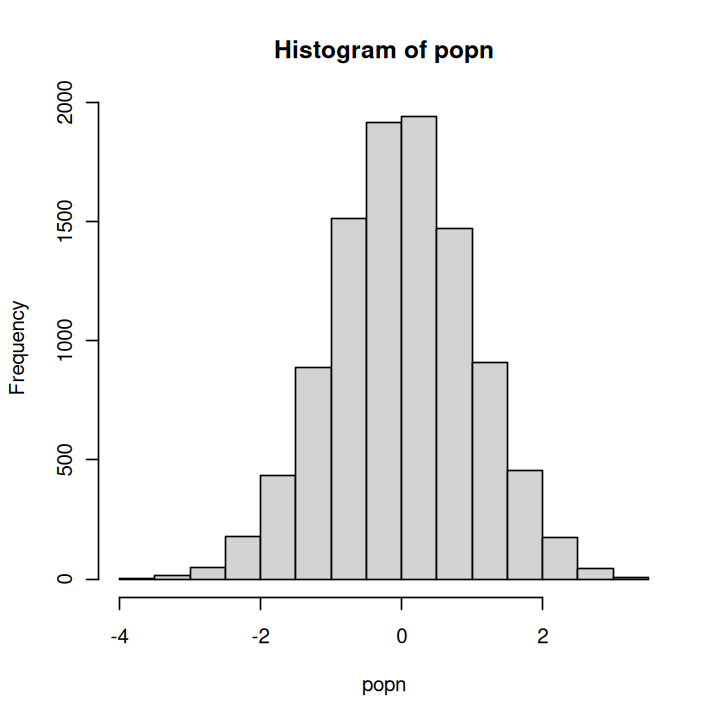

In [175]:
set.seed(12345)
popn <- rnorm(10000) # Generate the population
hist(popn)

And run and time the different functions:

In [176]:
n <- 100 # sample size for each experiment
num <- 10000 # Number of times to rerun the experiment

print("Using loops without preallocation on a vector took:" )
print(system.time(loopy_sample1(popn, n, num)))

print("Using loops with preallocation on a vector took:" )
print(system.time(loopy_sample2(popn, n, num)))

print("Using loops with preallocation on a list took:" )
print(system.time(loopy_sample3(popn, n, num)))

print("Using the vectorized sapply function (on a list) took:" )
print(system.time(sapply_sample(popn, n, num)))

print("Using the vectorized lapply function (on a list) took:" )
print(system.time(lapply_sample(popn, n, num)))

[1] "Using loops without preallocation on a vector took:"


   user  system elapsed 
  0.242   0.036   0.279 


[1] "Using loops with preallocation on a vector took:"


   user  system elapsed 
  0.143   0.127   0.269 


[1] "Using loops with preallocation on a list took:"


   user  system elapsed 
  0.131   0.117   0.248 


[1] "Using the vectorized sapply function (on a list) took:"


   user  system elapsed 
  0.134   0.130   0.264 


[1] "Using the vectorized lapply function (on a list) took:"


   user  system elapsed 
  0.141   0.114   0.255 


*Note that these times will be different on your computer because they depend on the computer's hardware and software (especially, the operating system), as well as what other processes are running.*

&#9733; run `sample.R` using `source` and/or `Rscript` and make sure it works.

rerun the script a few times, first by fixing the `n` and `num` parameters, and then also by varying them. Compare the times you get from these repeated runs of the script and think about which approach is the most efficient and why. Clearly, the loopy, without a pre-allocation approach is usually (but not always) going to be bad, while the others are pretty comparable.

#### The `tapply` function

Let's look at `tapply`, which is particularly useful because it allows you to apply a function to subsets of a vector in a dataframe, with the subsets defined by some other vector in the same dataframe, usually a factor (this could be useful for pound hill data analysis that's coming up, for example). 

This makes it a bit of a different member of the `*apply` family. Try this:

In [177]:
x <- 1:20 # a vector
x

[1]  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20

Now create a `factor` type variable (of the same length) defining groups:

In [178]:
y <- factor(rep(letters[1:5], each = 4)) 
y

[1] a a a a b b b b c c c c d d d d e e e e
Levels: a b c d e

Now add up the values in x within each subgroup defined by y:

In [179]:
tapply(x, y, sum)

a  b  c  d  e 
10 26 42 58 74

### Using `by`

You can also do something similar to `tapply` with the `by` function, i.e., apply a function to a dataframe using some factor to define the subsets. Try this:

First import some data:

In [180]:
attach(iris)
iris

Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
<dbl>,<dbl>,<dbl>,<dbl>,<fct>
5.1,3.5,1.4,0.2,setosa
4.9,3.0,1.4,0.2,setosa
4.7,3.2,1.3,0.2,setosa
4.6,3.1,1.5,0.2,setosa
5.0,3.6,1.4,0.2,setosa
5.4,3.9,1.7,0.4,setosa
4.6,3.4,1.4,0.3,setosa
5.0,3.4,1.5,0.2,setosa
4.4,2.9,1.4,0.2,setosa


Now run the `colMeans` function (it is better for dataframes than just mean) on multiple columns:

In [181]:
by(iris[,1:2], iris$Species, colMeans)

iris$Species: setosa
Sepal.Length  Sepal.Width 
       5.006        3.428 
------------------------------------------------------------ 
iris$Species: versicolor
Sepal.Length  Sepal.Width 
       5.936        2.770 
------------------------------------------------------------ 
iris$Species: virginica
Sepal.Length  Sepal.Width 
       6.588        2.974 

In [182]:
by(iris[,1:2], iris$Petal.Width, colMeans)

iris$Petal.Width: 0.1
Sepal.Length  Sepal.Width 
        4.82         3.36 
------------------------------------------------------------ 
iris$Petal.Width: 0.2
Sepal.Length  Sepal.Width 
    4.972414     3.379310 
------------------------------------------------------------ 
iris$Petal.Width: 0.3
Sepal.Length  Sepal.Width 
    4.971429     3.328571 
------------------------------------------------------------ 
iris$Petal.Width: 0.4
Sepal.Length  Sepal.Width 
    5.300000     3.785714 
------------------------------------------------------------ 
iris$Petal.Width: 0.5
Sepal.Length  Sepal.Width 
         5.1          3.3 
------------------------------------------------------------ 
iris$Petal.Width: 0.6
Sepal.Length  Sepal.Width 
         5.0          3.5 
------------------------------------------------------------ 
iris$Petal.Width: 1
Sepal.Length  Sepal.Width 
    5.414286     2.371429 
------------------------------------------------------------ 
iris$Petal.Width: 1.1
Sepal.Length  

### Using `replicate`

The `replicate` function is useful to avoid a loop for function that typically involves random number generation (more on this below). For example:

In [183]:
replicate(10, runif(5))

0.05779543,0.79875145,0.48499984,0.86907132,0.1283642,0.0009810759,0.6536405,0.8683811,0.8454915,0.8783501
0.45615105,0.57098740,0.23039036,0.30154024,0.2747319,0.2428520240,0.9098087,0.6079378,0.6468676,0.7984627
0.56282049,0.04613426,0.62504519,0.04747557,0.7813629,0.8418969549,0.4024599,0.6946761,0.6771371,0.2471511
0.47753585,0.69846828,0.46303515,0.25758230,0.2651486,0.1114152884,0.1513297,0.3396491,0.8450003,0.3601890
0.63433648,0.40640785,0.07475354,0.04436429,0.0915491,0.2450728263,0.4717760,0.4990844,0.7130802,0.9336190


That is, you just generated 10 sets (columns) of 5 uniformly-distributed random numbers (a 10 $\times$ 5 matrix). 

```{note}
The actual numbers you get will be different from the ones you see here unless you set the random number seed [as we learned above](r-random-numbers).
```

### Using `plyr` and `ddply`

The `plyr` package combines the functionality of the `*apply` family into a few handy functions. See the [official package overview](https://search.r-project.org/CRAN/refmans/plyr/html/plyr.html).

In particular, `ddply` is very useful, because for each subset of a data frame, it applies a function and then combines results into another data frame. In other words, "ddply" means: take a data frame, split it up, do something to it, and return a data frame. See the official [`ddply` reference](https://search.r-project.org/CRAN/refmans/plyr/html/ddply.html) and the [split-apply-combine paper](https://www.jstatsoft.org/article/view/v040i01) for examples. `ddply` can be slower than other vectorized methods, as it trades some speed for compactness of use. Overall, functions in `plyr` can be slow if you are working with very large datasets that involve a lot of subsetting (analyses by many groups or grouping variables). 

The base `*apply` functions remain useful and worth knowing even if you do get into `plyr` or better still, `dplyr`, which we will see in the [Data chapter](data-r.ipynb).


## Practical: a vectorization challenge

The ricker model is a classic discrete population model which was introduced in 1954 by ricker to model recruitment of stock in fisheries. It gives the expected number (or density) $N_{t+1}$ of individuals in generation $t + 1$ as a function of the number of individuals in the previous generation $t$:

$$ N_{t+1}= N_t e^{r\left(1-\frac{N_t}{k}\right)} $$

Here $r$ is intrinsic growth rate and $k$ as the carrying capacity of the environment. Try this script (call it `ricker.R` and save it to `code`) that runs it:

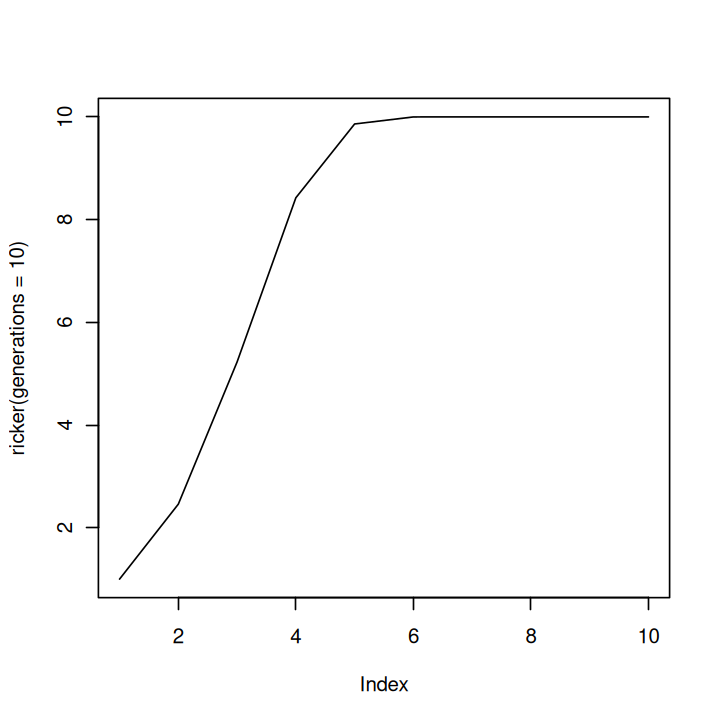

In [184]:
ricker <- function(N0=1, r=1, K=10, generations=50)
{
  # runs a simulation of the ricker model
  # returns a vector of length generations
  
  N <- rep(NA, generations)    # Creates a vector of NA
  
  N[1] <- N0
  for (t in 2:generations)
  {
    N[t] <- N[t-1] * exp(r*(1.0-(N[t-1]/K)))
  }
  return (N)
}

plot(ricker(generations=10), type="l")

Now open and run the script `vectorize2.R` (available on the MQB repository). This is the stochastic ricker model (compare with the above script to see where the stochasticity (random error) enters). Now modify the script to complete the exercise given. 
*Your goal is to come up with a solution better than mine!*       

## Errors and Debugging

As we learned in the [Python Chapter](Python:errors), fixing errors and debugging is an integral part of programming! And just like Python, a variety of debugging tools and functions are available in R.

### Tracing the error trail

When R encounters a runtime error, it will typically display the call "stack" (sequence) after the error occurs, helping you trace where the error happened.

Let's try an example (type and run it using your code editor):

In [185]:
# Define nested functions
outer_function <- function(a) {
  middle_function(a)
}

middle_function <- function(b) {
  inner_function(b)
}

inner_function <- function(c) {
  # Intentional error: division by zero
  result <- c / d
  return(result)
}

# Call the outer function
outer_function(1)

ERROR: Error in inner_function(b): object 'd' not found


The `Traceback` shows the sequence of function calls that led to the error, helping you pinpoint its origin.

```{tip}
If you do not get a traceback automatically, you an use the  `traceback()` function (run it after yout get the error) to find where the errors(s) are when a program crashes.
```

### Debugging using breakpoints 

Once you have found an error, you need to debug it. Assuming you have an idea about where (or the general area) in your code the error is, a simple way to debug is to use the  `browser()` function.  

Just like the `ipdb.set_tarce()` command in Python, `browser()` allows you to insert a breakpoint in your script and then step through your code. Place it within your script at the point you want to examine local variables  (e.g. inside a `for` loop). 

Let's look at an example usage of `browser()`. 

&#9733; Type the following in a script file called `browse.R` and save in `code`:

```r
Exponential <- function(N0 = 1, r = 1, generations = 10) {
  # runs a simulation of exponential growth
  # returns a vector of length generations
  
  N <- rep(NA, generations)    # Creates a vector of NA
  
  N[1] <- N0
  for (t in 2:generations) {
    N[t] <- N[t-1] * exp(r)
    browser()
  }
  return (N)
}

plot(Exponential(), type="l", main="Exponential growth")
```

Now run `browse.R` from the R console (using `source()`). 

The script will be run till the first iteration of the `for` loop and the R console will enter the browser mode, which looks like this:

```r
Browse[1]>
```

Now, you can examine the variables present at that point. Also, at the browser console, you can enter expressions as normal, or use a few particularly useful debug commands (similar to the Python debugger):

* `n`: execute the next line.
* `c`: exit browser and continue execution
* `Q`: exit browser and abort, return to top-level.
  
You can also inspect variables in the current state of the function run using `ls()` (try it).


### Using `debug()`

The `debug()` function flags a function for debugging; R will enter the browser mode every time the function is called.

Let's define a function with a bug (type and run it):

```r
buggy_function <- function(n) {
  result <- n + unknown_variable
  return(result)
}
```

Now enable debugging by running in the R console:

`debug(buggy_function)`

Now call the function:

`buggy_function(10)`

R will enter the browser mode at the beginning of `buggy_function()`. You can step through and inspect variables as you did in the `browser()` example above.

```{tip}
If you want to debug the function only once, use: `debugonce(buggy_function)`
```

```{tip}
IDEs like RStudio offer built-in debugging features such as breakpoints and step-through execution.
```

### Unit testing 

We will not cover unit testing here, which we [did in Python Chapter](Python:errors)). Unit testing in R is equally recommended, especially if you are going to develop complex code and packages.

```{tip}
A very convenient tool for R unit testing is [`testthat`](https://testthat.r-lib.org).
```

In addition, you can use other "[defensive programming](https://en.wikipedia.org/wiki/Defensive_programming)" methods in R to keep an eye on errors that might arise in special circumstances in an complex program. A good option for this is to convert warnings to errors using the [`stopifnot()`](https://stat.ethz.ch/r-manual/r-devel/library/base/html/stopifnot.html). This is a bit like `try` (which we will cover below, and we also covered in [Python Chapter](Python:errors)). 

### "Catching" errors

Often, you don't know if a simulation or a R function will work on a particular data or variable, or a value of a variable (can happen in many statistical functions). 

Indeed, as most of you must have already experienced by now, there can be frustrating, puzzling bugs in programs that lead to mysterious errors. Often, the error and warning messages you get are un-understandable, especially in R!

Rather than letting R stop the whole analysis, you may want to catch the error and continue. You can do this with `try()`. 

Let's try `try`! 

First, let's write a function:

In [186]:
doit <- function(x) {
    temp_x <- sample(x, replace = TRUE)
    if(length(unique(temp_x)) > 30) {#only take mean if sample was sufficient
         print(paste("Mean of this sample was:", as.character(mean(temp_x))))
        } 
    else {
        stop("Couldn't calculate mean: too few unique values!")
        }
    }

This function runs a simulation that involves sampling from a synthetic population with replacement and takes its mean, but *only* if at least 30 unique samples are obtained. Note that we have used another keyword here: `stop()`. Pay close attention to `sample()`, and `stop()` in the above script (check out what they are by using R help or searching online). 


Now, generate your population:

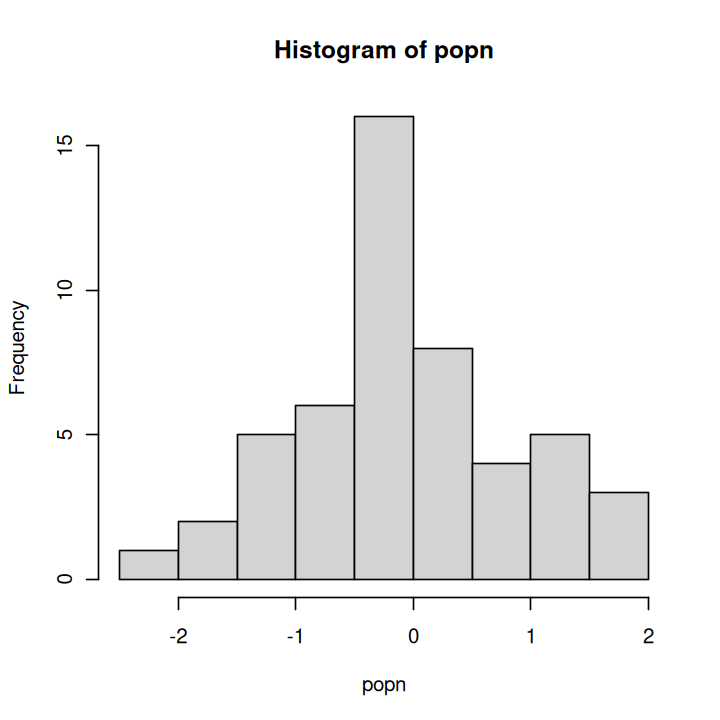

In [187]:
set.seed(1345) # again, to get the same result for illustration

popn <- rnorm(50)

hist(popn)

Now try running it using `lapply` as you did above, repeating the sampling exercise 15 times:

In [188]:
lapply(1:15, function(i) doit(popn))

[1] "Mean of this sample was: -0.11620822588674"
[1] "Mean of this sample was: -0.0468516755995931"
[1] "Mean of this sample was: -0.0890228211466614"
[1] "Mean of this sample was: -0.124229742255296"


ERROR: Error in doit(popn): Couldn't calculate mean: too few unique values!


Your result will be different than this (you would get between 0 - 15 samples; we got 4 here). But in most cases, the script will fail because of the `stop` command (on line 7 of the above function) at some iteration, returning less than the requested 15 mean values, followed by an error stating that the mean could not be calculated because too few unique values were sampled.

Now try doing the same using `try`:

In [189]:
result <- lapply(1:15, function(i) try(doit(popn), FALSE))

[1] "Mean of this sample was: 0.0314144452816157"
[1] "Mean of this sample was: -0.233476945796405"
[1] "Mean of this sample was: -0.196681538928001"
[1] "Mean of this sample was: 0.0146969612111605"
[1] "Mean of this sample was: -0.234913159471725"
[1] "Mean of this sample was: -0.0497464588165691"
Error in doit(popn) : Couldn't calculate mean: too few unique values!
[1] "Mean of this sample was: 0.14834078393269"
[1] "Mean of this sample was: -0.271626543849156"
[1] "Mean of this sample was: -0.0661949014450445"
[1] "Mean of this sample was: -0.162429229014161"
[1] "Mean of this sample was: -0.0962033633604762"
[1] "Mean of this sample was: -0.025525566612254"
[1] "Mean of this sample was: -0.196872015952289"
[1] "Mean of this sample was: 0.1902095255599"


In this run, you again asked for the means of 15 samples, and again you (most likely) got less than that (see the above example output). With the `try` command, the errors are caught and `lapply()` continues through each iteration. The `silent` argument of `try()` controls whether those errors are printed in the terminal. By default, `silent = FALSE`, so the messages are shown; use `silent = TRUE` to suppress them. *Remember to check the help for built-in R functions such as `try`.*

The errors are also stored in the object `result`:

In [190]:
class(result)

[1] "list"

This is a list that stores the result of each of the 15 runs, including the ones that ran into an error. Have a look at it:   

In [191]:
result

[[1]]
[1] "Mean of this sample was: 0.0314144452816157"

[[2]]
[1] "Mean of this sample was: -0.233476945796405"

[[3]]
[1] "Mean of this sample was: -0.196681538928001"

[[4]]
[1] "Mean of this sample was: 0.0146969612111605"

[[5]]
[1] "Mean of this sample was: -0.234913159471725"

[[6]]
[1] "Mean of this sample was: -0.0497464588165691"

[[7]]
[1] "Error in doit(popn) : Couldn't calculate mean: too few unique values!\n"
attr(,"class")
[1] "try-error"
attr(,"condition")
<simpleError in doit(popn): Couldn't calculate mean: too few unique values!>

[[8]]
[1] "Mean of this sample was: 0.14834078393269"

[[9]]
[1] "Mean of this sample was: -0.271626543849156"

[[10]]
[1] "Mean of this sample was: -0.0661949014450445"

[[11]]
[1] "Mean of this sample was: -0.162429229014161"

[[12]]
[1] "Mean of this sample was: -0.0962033633604762"

[[13]]
[1] "Mean of this sample was: -0.025525566612254"

[[14]]
[1] "Mean of this sample was: -0.196872015952289"

[[15]]
[1] "Mean of this sample was: 0.19

That's a lot output! But basically it tells you which runs ran into and error and why (no surprises here, of course!). You can also store the results "manually" by using a loop to do the same: 

In [192]:
result <- vector("list", 15) #Preallocate/Initialize
for(i in 1:15) {
    result[[i]] <- try(doit(popn), FALSE)
    }

[1] "Mean of this sample was: -0.123990166669901"
Error in doit(popn) : Couldn't calculate mean: too few unique values!
[1] "Mean of this sample was: 0.0818124335353191"
[1] "Mean of this sample was: -0.139655286435176"
[1] "Mean of this sample was: -0.0215429865826124"
Error in doit(popn) : Couldn't calculate mean: too few unique values!
[1] "Mean of this sample was: 0.00539838134322893"
Error in doit(popn) : Couldn't calculate mean: too few unique values!
[1] "Mean of this sample was: 0.146907839413106"
[1] "Mean of this sample was: -0.152002314653857"
[1] "Mean of this sample was: 0.0161321300360042"
[1] "Mean of this sample was: -0.241857872516043"
[1] "Mean of this sample was: -0.16077541901813"
[1] "Mean of this sample was: -0.0450988128783513"
[1] "Mean of this sample was: -0.162230652541811"


Now have a look at the new `result`; it will have similar content as the one you got from using `lapply`.

```{tip}
Also check out `tryCatch()`, which provides more control over error and warning handling, as an alternative to `try()`
```

&#9733; Type the above blocks of code illustrating `try` into a script file called `try.R` and save in `code`. The script, when `source`d, should run without errors (that is, don't run the sampling function without `try`!). 

## Packages

The big strength of R is that users can easily build and share packages through [cran.r-project.org](https://cran.r-project.org). 

There are R packages for practically all statistical and mathematical analysis you might conceive, so check them out before reinventing the wheel. Visit [cran.r-project.org](https://cran.r-project.org) and go to packages to see a list and a brief description. 

Install a package from the R console with `install.packages()`. Use your personal library as described in [R Installation and User Libraries](../appendices/r-setup.md).

For example:

```r
install.packages(c("tidyverse"))
```
You can also install multiple packages by concatenating their names: `install.packages(c("pack1","pack2","pack3"))`
(three packages in this hypothetical example)

Install packages from an ordinary R session into your personal library; do not launch R with `sudo`. If R asks to create a personal library, answer yes. See [R Installation and User Libraries](../appendices/r-setup.md#install-packages-without-running-r-as-administrator) for checks and troubleshooting.

You can also use the RStudio package interface, but it installs into the same R libraries: inspect `.libPaths()` when a package appears in one session but not another. Operating-system package managers are for system-managed packages and libraries, not a substitute for checking which R installation and user library you are using.

&#9733; Go ahead and install `tidyverse` if you don't have it yet. We will be using it [soon](./data-r.ipynb)!


### Building your own 

You can combine your code, data sets and documentation to make a *bona fide* R package. You may wish to do this for particularly large projects that you think will be useful for others. read the [*Writing R Extensions*](https://cran.r-project.org/doc/manuals/r-release/r-exts.html) manual and see *package.skeleton* to get started. 

The R tool set [EcoDataTools](https://github.com/DomBennett/EcoDataTools) and the package [cheddar](https://github.com/quicklizard99/cheddar) were written by Silwood Grad Students!

(r-observations-practice)=

## The observations practice

This exercise uses the same small table and the same rules as the Python exercise, so you can think about the choices being made rather than simply translate one language into another. Work in a disposable project containing `code`, `data`, and `results` directories. Download the {download}`ordinary observations <../data/bootcamp_observations.csv>`, {download}`boundary observations <../data/bootcamp_observations_boundary.csv>`, and {download}`invalid observations <../data/bootcamp_observations_invalid.csv>` into the `data` directory. Save your work as `code/observations_practice.R`, then run it from the project root with `Rscript code/observations_practice.R`.

### Guided: read, inspect, and decide what counts as valid

Read every column as character data first so validation happens before conversion:

```r
observations <- read.csv(
  "data/bootcamp_observations.csv",
  colClasses = "character", na.strings = "", check.names = FALSE
)
str(observations)
print(observations)
```

For this exercise, the columns must be `site,date,count`, in that order. Every row needs a site and date. An empty `count` means that the observation is missing; zero means that somebody looked and counted none; every other count must be a non-negative integer. The ordinary dataset deliberately contains one repeated row. Before writing any code, explain why a missing count and an observed zero must not be treated alike.

### Guided: validate before calculating

Write a `read_observations(path)` function. Check the exact column names, reject empty sites or dates, and use `grepl("^(0|[1-9][0-9]*)$", value)` on each non-missing count before converting it with `as.integer()`. Stop with an informative error when a rule fails. Run the function on `bootcamp_observations_invalid.csv` and confirm that it stops because `-1` is not a non-negative integer.

### Independent: deduplicate and summarise

Write `summarise_observations(data)` without looking at the Python solution. Remove exact duplicate rows once. For each site, report `total_known` (the sum of non-missing counts) and `missing_count` separately. If every count for a site is missing, `total_known` must be `NA`, not zero. Your results should be: A `(2, 1)`, B `(0, 0)`, C `(NA, 2)`, and D `(0, 0)`, where each pair is `(total_known, missing_count)`. Add `stopifnot()` checks for these four examples.

Create one reproducible base-R figure of known totals and save it under `results/`; make the all-missing case visible in the caption or annotation rather than silently plotting it as zero. Rerun the complete script in a fresh terminal.

### Critique and compare

Compare your R result with the {ref}`Python:observations-practice`. Which decisions should stay the same whichever language you use, and which arise from the way R or Python works? Use the following examples to begin your critique:

- **Missing is not zero.** Replacing every `NA` with `0` might seem to simplify the calculation, but it changes what the data mean. There is a subtler trap too: `sum(c(NA_integer_, NA_integer_), na.rm = TRUE)` returns `0`. Why is that misleading for site C, where neither count was observed? Explain when removing missing values is useful and what you must check before interpreting the sum. Which of your tests would catch an all-missing site being reported as zero?

- **A repeated row is not another observation.** After count validation and conversion, site A's counts in the ordinary file are `c(2L, NA_integer_, 2L)`. Summing them with `na.rm = TRUE` before removing the exact duplicate gives `4`, rather than the expected `2`. Why would checking only the number of sites fail to detect this mistake? Identify a check that would detect it, and explain why removing duplicate count values alone is not the same as removing duplicate rows: two genuine observations can have the same count.

- **An error should help somebody locate the problem.** Compare `Invalid input` with `bootcamp_observations_invalid.csv: CSV line 2, column 'count': found '-1'; expected an empty field or a non-negative integer.` Here, CSV line 1 is the header. Which details would help you find the offending entry and understand the rule it breaks? Draft a similarly useful message for the `many` entry on CSV line 3. Report the problem rather than silently replacing the value or guessing a correction.

## Climate-data practicals

### Practical: is Florida getting warmer?

*This Practical assumes you have at least a basic understanding of [correlation coefficients](regress:correlations) and [p-values](t-f-tests.ipynb).*

Your goal is to write an R script that will help answer the question: *Is Florida getting warmer*?  

Save the script as `code/Florida.R`. Download {download}`the Key West annual-mean temperature data <../data/key_west_annual_mean_temperature.RData>` into `data/` in a project with `code/`, `data/` and `results/` directories. Run it from the project root with `Rscript code/Florida.R`.

To answer the question, you need to calculate the [correlation coefficients](regress:correlations) between temperature and time. However, you can't use the standard p-value calculated for a correlation coefficient, because measurements of climatic variables in successive time-points in a time series (successive seconds, minutes, hours, months, years, etc.) are *not independent*. Therefore you will use a permutation analysis instead, by generating a distribution of random correlation coefficients and compare your observed coefficient with this random distribution.  

Some guidelines:

 * Load and examine the annual temperature dataset from Key West in Florida, USA for the 20th century:

In [193]:
rm(list=ls())

load("data/key_west_annual_mean_temperature.RData")

ls()

[1] "ats"

In [194]:
class(ats)

[1] "data.frame"

In [195]:
head(ats)

,Year,Temp
,<int>,<dbl>
1,1901,23.75000
2,1902,24.66667
3,1903,24.71667
4,1904,24.51667
5,1905,24.88333
6,1906,24.63333


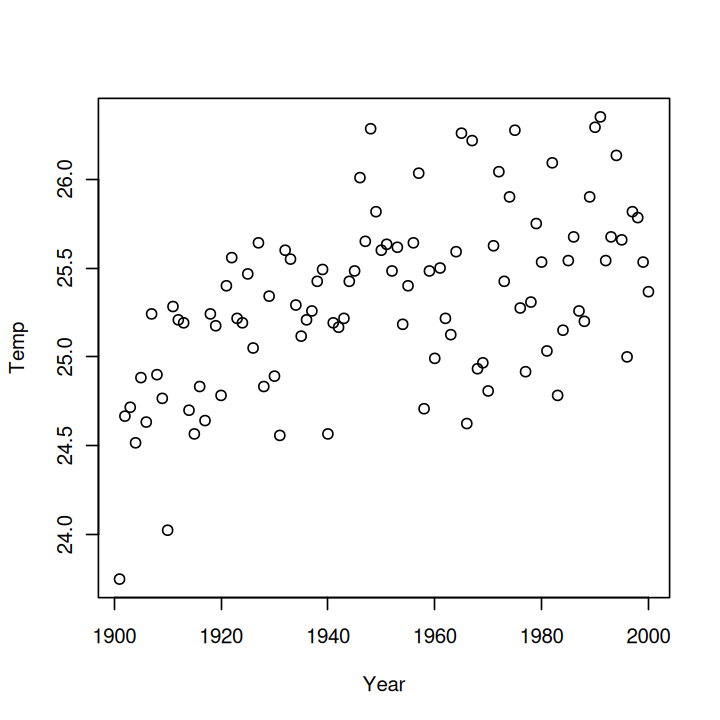

In [196]:
plot(ats)

Then, 
* Compute the appropriate correlation coefficient between years and Temperature and store it (look at the help file for `cor()`
* repeat this calculation a *sufficient* number of times, each time randomly reshuffling the temperatures (i.e., randomly re-assigning temperatures to years), and recalculating the correlation coefficient (and storing it) 

```{tip}
You can use the `sample` function that we learned about above to do the shuffling. read the help file for this function and experiment with it. 
``` 
*  Calculate what fraction of the random correlation coefficients were greater than the observed one (this is your approximate, asymptotic p-value).

* *Interpret and present the results*: Present your results and their interpretation in a pdf document written in $\LaTeX$ (save the document's source code alongside the PDF) (*Keep the writeup, including any figures, to one A4 page*).

### Group practical: autocorrelation in Florida weather


*This Practical assumes you have at least a basic understanding of [correlation coefficients](regress:correlations) and [p-values](t-f-tests.ipynb).*

Download {download}`the Key West annual-mean temperature data <../data/key_west_annual_mean_temperature.RData>` into `data/` in a project with `code/`, `data/` and `results/` directories. Write `code/TAutoCorr.R`, run it from the project root and save the results in `results/`. Your goal is to answer the question: *Are temperatures of one year significantly correlated with the next year (successive years), across years in a given location*? 

To answer this question, you need to calculate the correlation between \(n-1\) pairs of years, where $n$ is the total number of years. However, here again, you can't use the standard p-value calculated for a correlation coefficient, because measurements of climatic variables in successive time-points in a time series (successive seconds, minutes, hours, months, years, etc.) are *not independent*. 

The general guidelines are:

* Compute the appropriate correlation coefficient between successive years and store it (look at the help file for `cor()`
* repeat this calculation *a sufficient number of* times by &ndash; randomly permuting the time series, and then recalculating the correlation coefficient for each randomly permuted sequence of annual temperatures and storing it.  
*  Then calculate what fraction of the correlation coefficients from the previous step were greater than that from step 1 (this is your approximate p-value).
* *Interpret and present the results* Present your results and their interpretation in a pdf document written in $\LaTeX$ (save the document's source code alongside the PDF).


<!-- ### Practicals wrap-up
  
* review and make sure you can run all the commands, code fragments, and named scripts we have built till now and get the expected outputs.

* Annotate/comment your code lines as much and as often as necessary using #.
    
* Keep all files organized in `code`, `data`and `results` directories

-->

## Readings & Resources

Check the readings under the R directory in the MQB repository. Also, search online for "R tutorial", and plenty will pop up. Choose ones that seem the most intuitive to you. * *remember, all R packages come with pdf guides/documentation!*

### R as a Programming language

* There are excellent websites besides cran. In particular, check out 
[statmethods.net](https://www.statmethods.net/) and the [R Wiki](https://en.wikibooks.org/wiki/r_Programming).     
* https://blog.sellorm.com/2017/12/18/learn-to-write-command-line-utilities-in-r/
* https://www.r-bloggers.com/2019/11/r-scripts-as-command-line-tools/

### Mathematical modelling and Stats in R 

* The Use R! series (all yellow books) by Springer are really good. In particular, consider: "A Beginner's Guide to R", "R by Example", "Numerical Ecology With R", "ggplot2" (coming up in the [Visualization Chapter](data-r.ipynb), "A Primer of Ecology with R", "Nonlinear Regression with R", and "Analysis of Phylogenetics and Evolution with R".
* For more focus on dynamical models: Soetaert & Herman. 2009 "A practical guide to ecological modelling: using R as a simulation platform".

### Debugging

* [`testthat`](https://testthat.r-lib.org/): Unit testing for R by Hadley Wickham (also developer of the `tidyverse` package, including `ggplot`).
* [Notes on debugging in R by Wickham](https://adv-r.hadley.nz/debugging.html)
* A good [overview of debugging methods in R with examples](https://data-flair.training/blogs/debugging-in-r-programming) 
*  [An introduction to the Interactive Debugging Tools in R](http://www.biostat.jhsph.edu/~rpeng/docs/r-debug-tools.pdf) by roger D Peng. 
* If you are using RStudio, [see this](https://support.rstudio.com/hc/en-us/articles/205612627-Debugging-with-RStudio).

### Sweave and knitr, and beyond

Tools built around R allow you to write a dissertation or another document that updates automatically when an embedded analysis, simulation or calculation changes. Instead of inserting a prefabricated graph or table, the source document contains the R code needed to create it. When the document is rendered, the output is generated and inserted into the final PDF or HTML file. This supports a genuinely reproducible workflow. To learn more, see:

*  [Sweave and knitr](https://support.rstudio.com/hc/en-us/articles/200552056-Using-Sweave-and-knitr) and [this](http://yihui.name/knitr/)
* [Quarto](https://quarto.org/)